## Proyecto pisos Madrid (Hito 2)

Fases CRISP-DM cubiertas: entendimiento, preparación, modelado y entrenamiento.

### Objetivo

Predecir el precio del **alquiler** de inmuebles en la Comunidad de Madrid.

Ciclo CRISP-DM (6 fases):

1. Objetivos de negocio y requisitos
2. Estudio de las variables disponibles
3. Limpieza y transformación del dataset
4. Modelado y entrenamiento
5. Comparación de modelos frente a los objetivos
6. Despliegue y monitoreo (fuera de este hito)


In [1]:
import re
import warnings
warnings.filterwarnings("ignore")
import pandas as pd
import numpy as np
from IPython.display import display
import seaborn as sns
import matplotlib.pyplot as plt
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import sklearn as sk
from sklearn.base import clone
from sklearn.compose import make_column_selector, make_column_transformer
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, PowerTransformer
from sklearn.model_selection import (
    train_test_split, cross_validate, KFold, StratifiedKFold, RandomizedSearchCV
)
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.neighbors import KNeighborsRegressor, KNeighborsClassifier
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.metrics import (
    r2_score, mean_squared_error, mean_absolute_error, root_mean_squared_error,
    accuracy_score, f1_score, precision_score, recall_score,
    classification_report, confusion_matrix,
    ConfusionMatrixDisplay,
)


In [2]:
# cargamos el dataset y mostramos las primeras filas.
df = pd.read_csv('20221108_1667901786.csv')
df.head()

,web_id,url,title,type,price,deposit,private_owner,professional_name,floor_built,floor_area,...,terrace,balcony,storeroom,swimming_pool,garden_area,location,district,subdistrict,postalcode,last_update
0,99439319,https://www.idealista.com/en/inmueble/99439319/,"Flat / apartment for rent in pablo luna, 4",Flat,1400,NaN,False,Silcasas Ochocientas,60,NaN,...,True,False,False,False,False,"pablo luna, 4, Subdistrict Castilla, District ...",Chamartín,Castilla,28046.0,7 November
1,99439586,https://www.idealista.com/en/inmueble/99439586/,Penthouse for rent in calle de Bolivia,Penthouse,1300,1.0,False,Cruzity,77,NaN,...,False,False,False,False,False,"Calle de Bolivia, Subdistrict Bernabéu-Hispano...",Chamartín,Bernabéu-Hispanoamérica,28016.0,7 November
2,99439169,https://www.idealista.com/en/inmueble/99439169/,Duplex for rent in calle de la constancia,Duplex,950,1.0,False,Mm Home,72,68.0,...,True,False,False,False,False,"Calle de la constancia, Urb. no, Subdistrict P...",Chamartín,Prosperidad,28002.0,7 November
3,26925909,https://www.idealista.com/en/inmueble/26925909/,"Flat / apartment for rent in Urb. el viso, El ...",Flat,2975,1.0,False,B&H Partners,160,NaN,...,True,False,False,True,False,"Urb. el viso, Subdistrict El Viso, District Ch...",Chamartín,El Viso,NaN,7 November
4,99440018,https://www.idealista.com/en/inmueble/99440018/,Studio flat for rent in luis cabrera,Studio,650,1.0,False,Madrid en Propiedad,30,NaN,...,False,True,False,False,False,"luis cabrera, Subdistrict Prosperidad, Distric...",Chamartín,Prosperidad,28002.0,7 November


In [3]:
df.head().T

,0,1,2,3,4
web_id,99439319,99439586,99439169,26925909,99440018
url,https://www.idealista.com/en/inmueble/99439319/,https://www.idealista.com/en/inmueble/99439586/,https://www.idealista.com/en/inmueble/99439169/,https://www.idealista.com/en/inmueble/26925909/,https://www.idealista.com/en/inmueble/99440018/
title,"Flat / apartment for rent in pablo luna, 4",Penthouse for rent in calle de Bolivia,Duplex for rent in calle de la constancia,"Flat / apartment for rent in Urb. el viso, El ...",Studio flat for rent in luis cabrera
type,Flat,Penthouse,Duplex,Flat,Studio
price,1400,1300,950,2975,650
deposit,NaN,1.0,1.0,1.0,1.0
private_owner,False,False,False,False,False
professional_name,Silcasas Ochocientas,Cruzity,Mm Home,B&H Partners,Madrid en Propiedad
floor_built,60,77,72,160,30
floor_area,NaN,NaN,68.0,NaN,NaN


In [4]:
# revisamos el tamaño del dataframe y la información de las columnas: tipos de datos y valores nulos.
df.info()
df.shape

<class 'pandas.DataFrame'>
RangeIndex: 9229 entries, 0 to 9228
Data columns (total 32 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   web_id             9229 non-null   int64  
 1   url                9229 non-null   str    
 2   title              9229 non-null   str    
 3   type               9229 non-null   str    
 4   price              9229 non-null   int64  
 5   deposit            5407 non-null   float64
 6   private_owner      9229 non-null   bool   
 7   professional_name  7622 non-null   str    
 8   floor_built        9229 non-null   int64  
 9   floor_area         3938 non-null   float64
 10  floor              8908 non-null   str    
 11  year_built         2893 non-null   float64
 12  orientation        4411 non-null   str    
 13  bedrooms           9229 non-null   int64  
 14  bathrooms          9229 non-null   int64  
 15  second_hand        9229 non-null   bool   
 16  lift               9229 non-null   

(9229, 32)

**Los tipos de dato orientan el EDA.**

Algunas columnas llegan como numéricas y se comportan como categóricas.

Tipos en este dataframe: `bool`, `int64`, `float64`, `str`.

`postalcode` llega como decimal. Es un código de área, no una cantidad. Lo pasamos a `Int64` (entero nullable) y luego a `str`.

`deposit` es distinto: los valores son meses de fianza (tienen orden). En la fuente lo dejamos como `Int64` nullable. En el modelado, la ausencia informa: no se imputa como número. Creamos `deposit_missing` y tratamos `deposit` como categoría explícita.


In [5]:
df['postalcode'] = df['postalcode'].astype('Int64').astype('string').str.zfill(5)

df['postalcode'].head()

0    28046
1    28016
2    28002
3     <NA>
4    28002
Name: postalcode, dtype: string

In [6]:
# deposit: ordinal con ausencia informativa. Int64 hasta flag + categoría en df_model.
# No imputar aquí ni convertir a 0.
df['deposit'] = df['deposit'].astype('Int64')

df['deposit'].head()

0    <NA>
1       1
2       1
3       1
4       1
Name: deposit, dtype: Int64

In [7]:
# usamos describe para obtener un resumen estadístico del contenido del dataframe.
df.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
web_id,9229.0,NaN,NaN,NaN,91330773.540254,20166543.03741,390273.0,95789278.0,98918477.0,99299041.0,99445941.0
url,9229,9229,https://www.idealista.com/en/inmueble/99439319/,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
title,9229,5826,Flat / apartment for rent in Castellana,53,NaN,NaN,NaN,NaN,NaN,NaN,NaN
type,9229,10,Flat,7361,NaN,NaN,NaN,NaN,NaN,NaN,NaN
price,9229.0,NaN,NaN,NaN,1937.995883,1615.063308,400.0,1000.0,1400.0,2300.0,25000.0
deposit,5407.0,<NA>,<NA>,<NA>,1.470686,0.622239,1.0,1.0,1.0,2.0,6.0
private_owner,9229,2,False,7622,NaN,NaN,NaN,NaN,NaN,NaN,NaN
professional_name,7622,1580,Home Club,405,NaN,NaN,NaN,NaN,NaN,NaN,NaN
floor_built,9229.0,NaN,NaN,NaN,110.285405,87.183901,0.0,60.0,85.0,127.0,990.0
floor_area,3938.0,NaN,NaN,NaN,94.357288,72.822703,0.0,54.0,75.0,110.0,995.0


- `floor` mezcla formatos (`str`, `int64` y nulos). Hay que limpiarla.

- `year_built` incluye años muy antiguos. En Madrid hay fincas del XIX; aun así, conviene validar antes de fiarse del extremo bajo.

- `garden_area` solo tiene `False`. No aporta varianza.

- `floor_built` llega a 0 m2. Esos mínimos conviene pasarlos a NaN (error de registro).


In [8]:
# convertimos las columnas categóricas a tipo 'category' para optimizar el uso de memoria.
categorical_cols = [
    "type",
    "orientation",
    "district",
    "subdistrict",
    "postalcode",
]

for col in categorical_cols:
    df[col] = df[col].astype("string").astype("category")

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 9229 entries, 0 to 9228
Data columns (total 32 columns):
 #   Column             Non-Null Count  Dtype   
---  ------             --------------  -----   
 0   web_id             9229 non-null   int64   
 1   url                9229 non-null   str     
 2   title              9229 non-null   str     
 3   type               9229 non-null   category
 4   price              9229 non-null   int64   
 5   deposit            5407 non-null   Int64   
 6   private_owner      9229 non-null   bool    
 7   professional_name  7622 non-null   str     
 8   floor_built        9229 non-null   int64   
 9   floor_area         3938 non-null   float64 
 10  floor              8908 non-null   str     
 11  year_built         2893 non-null   float64 
 12  orientation        4411 non-null   category
 13  bedrooms           9229 non-null   int64   
 14  bathrooms          9229 non-null   int64   
 15  second_hand        9229 non-null   bool    
 16  lift             

In [9]:
# ajustamos los tipos antes de crear la copia de trabajo.
df["price"] = df["price"].astype("float64")

# year_built es entero con ausencias: Int64 conserva los nulos sin imputar.
df["year_built"] = df["year_built"].astype("Int64")

# la copia de trabajo hereda los tipos ya normalizados.
df_clean = df.copy()

In [10]:
# separamos numéricas de categóricas.
col_numericas = df.select_dtypes(include=[np.number]).columns.tolist()
col_categoricas = df.select_dtypes(include=['str', 'object', 'bool', 'category']).columns.tolist()

print(f"columnas numéricas: {col_numericas}\ncolumnas categóricas: {col_categoricas}")

columnas numéricas: ['web_id', 'price', 'deposit', 'floor_built', 'floor_area', 'year_built', 'bedrooms', 'bathrooms']
columnas categóricas: ['url', 'title', 'type', 'private_owner', 'professional_name', 'floor', 'orientation', 'second_hand', 'lift', 'garage_included', 'furnished', 'equipped_kitchen', 'fitted_wardrobes', 'air_conditioning', 'terrace', 'balcony', 'storeroom', 'swimming_pool', 'garden_area', 'location', 'district', 'subdistrict', 'postalcode', 'last_update']


Algunas numéricas se comportan como categóricas. Otras no predicen. En este dataset:

- **postalcode:** código de área, no cantidad. A `str`/`category`.

- **web_id:** identificador. Fuera del modelo.

- **deposit:** baja cardinalidad y orden (meses de fianza). Fuente: `Int64` nullable. Modelo: `deposit_missing` + categoría explícita para no confundir `0` con `no_informado`.

En el encoding cuidamos la cardinalidad: baja y alta, para no sobreajustar.


In [11]:
# resumen de valores nulos por columna.
resumen_nulos = pd.DataFrame({
    "dtype": df_clean.dtypes.astype(str),
    "nulos": df_clean.isna().sum(),
    "porcentaje_nulos": df_clean.isna().mean().mul(100).round(2),
})

resumen_nulos[resumen_nulos["nulos"] > 0].sort_values("porcentaje_nulos")

,dtype,nulos,porcentaje_nulos
district,category,133,1.44
floor,str,321,3.48
subdistrict,category,771,8.35
professional_name,str,1607,17.41
postalcode,category,2395,25.95
deposit,Int64,3822,41.41
orientation,category,4818,52.21
floor_area,float64,5291,57.33
year_built,Int64,6336,68.65


In [12]:
# verificamos que los nulos de professional_name coinciden con private_owner=True.
pd.crosstab(
    df_clean["private_owner"],
    df_clean["professional_name"].isna(),
    rownames=["private_owner"],
    colnames=["professional_name_missing"],
)

professional_name_missing,False,True
private_owner,,
False,7622,0
True,0,1607


No todos los nulos se tratan igual. El EDA conserva los nulos de origen. En `df_model`, las categóricas sin dato van a categorías explícitas; las numéricas se imputan en el pipeline. Excepción: `deposit` pasa a categoría `no_informado` más `deposit_missing`.

- `year_built` (68,65% nulos): la más incompleta. Se queda como `Int64` nullable; imputación en el pipeline.

- `floor_area` (57,33%): no es idéntica a `floor_built`. Flag de ausencia + imputación en pipeline.

- `orientation` (52,21%): en `df_model` va a `"desconocido"`. No implica que el inmueble no tenga orientación.

- `deposit` (41,41%): no sabemos si no hay fianza o no se informó. Conservamos el ordinal, creamos `deposit_missing` y codificamos ausencia como `no_informado`. Sin mediana ni `0`.

- `postalcode` (25,95%): categoría `"desconocido"` en `df_model`.

- `professional_name` (17,41%): ausencia estructural; coincide con `private_owner=True` (crosstab). Columna redundante.

- `subdistrict` / `district` (8,35% / 1,44%): `"desconocido"` en `df_model`. Podrían recuperarse desde `location`.

- `floor` (3,48% nulos) además de formatos mixtos (`1st`, `ground`, `141`...). Se limpia en preparación.


In [13]:
# creamos un resumen de las columnas numéricas.
resumen_numericas = pd.DataFrame({
    "dtype": df[col_numericas].dtypes.astype(str),
    "no_nulos": df[col_numericas].notna().sum(),
    "n_unicos": df[col_numericas].nunique(dropna=True)
})

resumen_numericas["porcentaje_unicos"] = (
    resumen_numericas["n_unicos"]
    / resumen_numericas["no_nulos"]
    * 100
).round(2)

resumen_numericas.sort_values("n_unicos")

,dtype,no_nulos,n_unicos,porcentaje_unicos
deposit,Int64,5407,6,0.11
bedrooms,int64,9229,13,0.14
bathrooms,int64,9229,15,0.16
year_built,Int64,2893,129,4.46
floor_area,float64,3938,284,7.21
floor_built,int64,9229,392,4.25
price,float64,9229,654,7.09
web_id,int64,9229,9229,100.00


Lectura de la tabla:

- `web_id`: 100% ids únicos. Fuera del df.

- `price`: target. Sin nulos. 654 valores únicos.

- `bedrooms` y `bathrooms`: sin nulos.

- `floor_area`: 5.291 faltantes. Flag + imputación en pipeline, no en el dataset crudo.

- `year_built`: 6.336 faltantes. Flag y/o imputación en pipeline.

- `floor_built`: sin nulos, 392 únicos. Mínimos de 0 m2 → nulos en limpieza.

- `deposit`: 3.822 sin fianza informada. `deposit_missing=1` y categoría `no_informado`. Sin inventar un número.


In [14]:
bool_cols = df_clean.select_dtypes(include=[bool]).columns.tolist()

resumen_bool = pd.DataFrame({
    "dtype": df_clean[bool_cols].dtypes.astype(str),
    "no_nulos": df_clean[bool_cols].notna().sum(),
    "True": df_clean[bool_cols].sum(),
    "False": (df_clean[bool_cols] == False).sum(),
})

resumen_bool["True%"] = (resumen_bool["True"] / resumen_bool["no_nulos"] * 100).round(2)
resumen_bool["False%"] = (resumen_bool["False"] / resumen_bool["no_nulos"] * 100).round(2)

resumen_bool

,dtype,no_nulos,True,False,True%,False%
private_owner,bool,9229,1607,7622,17.41,82.59
second_hand,bool,9229,9200,29,99.69,0.31
lift,bool,9229,8742,487,94.72,5.28
garage_included,bool,9229,3114,6115,33.74,66.26
furnished,bool,9229,8739,490,94.69,5.31
equipped_kitchen,bool,9229,8739,490,94.69,5.31
fitted_wardrobes,bool,9229,6675,2554,72.33,27.67
air_conditioning,bool,9229,6320,2909,68.48,31.52
terrace,bool,9229,3318,5911,35.95,64.05
balcony,bool,9229,1650,7579,17.88,82.12


Booleanas: sin nulos. Lectura:

- `second_hand`: 99,69% segunda mano. La dejamos por si la obra nueva marca precio distinto.

- `furnished` y `equipped_kitchen`: mismos conteos. Unificamos para no duplicar señal.

- `garden_area`: varianza nula. Fuera del training.

- `private_owner`: 17,41% particulares / 82,59% agencias. Candidata fuerte.

- `garage_included`: 33,74%. Separa gamas.

- `swimming_pool`: 25,43%. Separa rangos de precio.

- `storeroom`: 76,90% sin trastero. Segmenta.

- `air_conditioning`: 68,48% con A/C. Varianza útil.

- `balcony`: 17,88%. Entra al training (luego será target de clasificación).

- `terrace`: 35,95%. Distinta de balcón; pueden coexistir.

- `fitted_wardrobes`: 27,67% sin armarios. Segmenta gamas.

- `lift`: solo 5,28% sin ascensor. Entra al training.


In [15]:
# comprobamos si las columnas 'furnished' y 'equipped_kitchen' son exactamente iguales.
son_identicas = df_clean['furnished'].equals(df_clean['equipped_kitchen'])
if son_identicas == True:
    print("sí, son exactamente iguales, podemos quitarlas del df.")

sí, son exactamente iguales, podemos quitarlas del df.


In [16]:
# eliminamos columnas de ruido, redundantes o irrelevantes para el modelo.
columns_to_drop = [
    "web_id",
    "url",
    "title",
    "professional_name",
    "equipped_kitchen",
    "garden_area"
]

df_clean = df_clean.drop(columns=columns_to_drop)
df_clean.shape

(9229, 26)

Tras seleccionar columnas, pasamos al análisis visual para ver qué relaciones ayudan a predecir `price`.


# Análisis exploratorio visual

Correlaciones y distribuciones en `df_clean` antes de preparar el training.


## 1. Análisis univariante

Miramos cada variable sola: distribución, asimetría y outliers. Eso condiciona transformaciones y la elección del modelo sobre `price`.


In [17]:
# distribución y outliers de las variables numéricas del df_clean (interactivo: hover sobre los puntos para datos estadísticos sobre cada subplot).
num_cols = df_clean.select_dtypes(include=[np.number]).columns.tolist()
print(num_cols)

rows = int(np.ceil(len(num_cols) / 4))
fig = make_subplots(rows=rows, cols=4, subplot_titles=num_cols)

for i, col in enumerate(num_cols):
    fig.add_trace(
        go.Box(y=df_clean[col], name=col, boxpoints="outliers", marker=dict(size=3)),
        row=i // 4 + 1, col=i % 4 + 1,
    )

# ocultamos el hueco libre del grid (7 variables en 2x4).
for i in range(len(num_cols), rows * 4):
    fig.update_xaxes(visible=False, row=i // 4 + 1, col=i % 4 + 1)
    fig.update_yaxes(visible=False, row=i // 4 + 1, col=i % 4 + 1)

fig.update_layout(height=700, showlegend=False, title_text="Boxplots numéricos interactivos")
fig.show()

['price', 'deposit', 'floor_built', 'floor_area', 'year_built', 'bedrooms', 'bathrooms']


Unidades: área en m2, precio en €/mes, baños y habitaciones en unidades.

- `price`: cola larga a la derecha. Los outliers son alquileres altos reales, no errores. En modelado usamos transformación (Yeo-Johnson / log).

- `floor_built` y `floor_area`: misma asimetría. Mínimo 0 m2 → error o ausencia, no outlier.

- `year_built`: extremos bajos en 1800–1890. Parecen relleno. Imputar como ausentes o eliminar en preparación.

- `bedrooms` y `bathrooms`: rangos normales, con extremos que podrían ser lujo. Revisar en preparación sin asumir.

- `deposit`: parece numérica, pero es ordinal (meses de fianza) y de baja cardinalidad. En modelado: categoría + `deposit_missing` + `no_informado`. Sin mediana ni confundir ausencia con `0`.

Los outliers de precio y superficie están en la cola alta. Estrategia: transformar el target y validar con robustez. **No descartamos la gama alta; reducimos error ahí y mejoramos la mayoría de predicciones.**


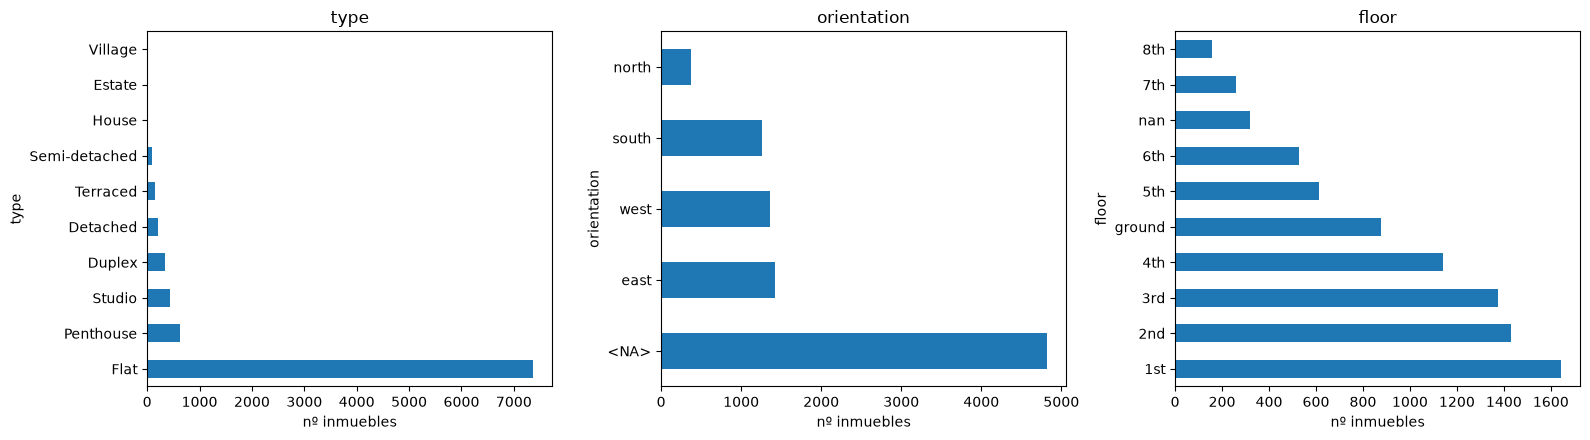

In [18]:
# distribución y frecuencias de las variables categóricas.
cat_cols = ['type', 'orientation', 'floor']

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, col in zip(axes, cat_cols):
    df_clean[col].value_counts(dropna=False).head(10).plot.barh(ax=ax)
    ax.set_title(col)
    ax.set_xlabel('nº inmuebles')
plt.tight_layout()
plt.show()

**Categóricas y booleanas:**

- `type`: ~80% `Flat`, pero discrimina fuerte. Medianas: Studio 850 € → House 5.500 € (Detached 3.900 €, Penthouse 1.800 €). En encoding, agrupamos rarezas (`Village`, `Estate`, `House`, <10 casos) en `otro`.

- `orientation`: 52% nulos y desbalance (north 373 frente a ~1.400 en el resto). El nulo informa: mediana sin orientación 1.365 € frente a west 1.500 € / east 1.490 € (anuncios menos cuidados). Ausencia como categoría propia (`sin_dato`), no moda.

- `floor`: 199 categorías. Demasiado para una planta. Primero clasificamos por patrón de formato y rastreamos anómalos.


In [19]:
# clasificamos cada valor de floor por su formato.
floor = df_clean["floor"].astype("string")

ordinales = floor.str.fullmatch(r"\d+(st|nd|rd|th)")            # '1st', '22nd'...
especiales = floor.isin(["ground", "basement", "semi-basement"])
enteros = floor.str.fullmatch(r"[\d,]+").fillna(False) & ~ordinales.fillna(False)  # '141', '1,000'...

print(f"categorías únicas: {floor.nunique()}, nulos: {floor.isna().sum()}")
print(f"ordinales válidos: {ordinales.sum()} ({ordinales.mean():.1%})")
print(f"especiales: {especiales.sum()}, enteros sospechosos: {enteros.sum()} ({enteros.mean():.1%})")

categorías únicas: 198, nulos: 321
ordinales válidos: 7464 (83.8%)
especiales: 876, enteros sospechosos: 563 (6.1%)


In [20]:
# hipótesis: los enteros 'imposibles' son otra variable colada en la columna.
# comprobamos fila a fila si coinciden con las numéricas candidatas.
sosp = df_clean.loc[enteros, ["floor", "floor_area", "floor_built", "price"]].copy()
sosp["floor_num"] = sosp["floor"].str.replace(",", "", regex=False).astype(int)

for col in ["floor_area", "floor_built", "price"]:
    print(f"coincide con {col}: {(sosp['floor_num'] == sosp[col]).sum()}/{len(sosp)}")

sosp.head(8)

coincide con floor_area: 0/563
coincide con floor_built: 339/563
coincide con price: 0/563


,floor,floor_area,floor_built,price,floor_num
8,141,140.0,141,3895.0,141
20,82,75.0,82,1050.0,82
22,252,210.0,252,3500.0,252
28,120,100.0,120,1750.0,120
62,55,45.0,55,1300.0,55
63,45,35.0,45,1150.0,45
70,215,140.0,215,2500.0,215
75,2,NaN,90,2100.0,2


El 60% de los enteros sospechosos coincide con `floor_built`: son **m2 colados en la columna de planta**, no plantas imposibles. Cuatro familias:

| Familia | Ejemplos | Casos | Tratamiento |
|---|---|---|---|
| ordinales en inglés | `'1st'`…`'30th'` | 7.464 (81%) | extraer el número |
| especiales | `'ground'`, `NaN` | 1.197 (13%) | mapear a 0 / `sin_dato` |
| m2 de `floor_built` | `141`, `871` | 339+ | `floor = NaN` (superficie ya está en su columna) |
| otros errores | `'1,000'`, `'floor'` | ~20 | `NaN` / `sin_dato` |

**Decisión:** ~94% de `floor` se salva como **numérica ordinal** (0…30). Así el modelo ve el orden de plantas, imposible con 199 categorías. Limpieza en preparación.


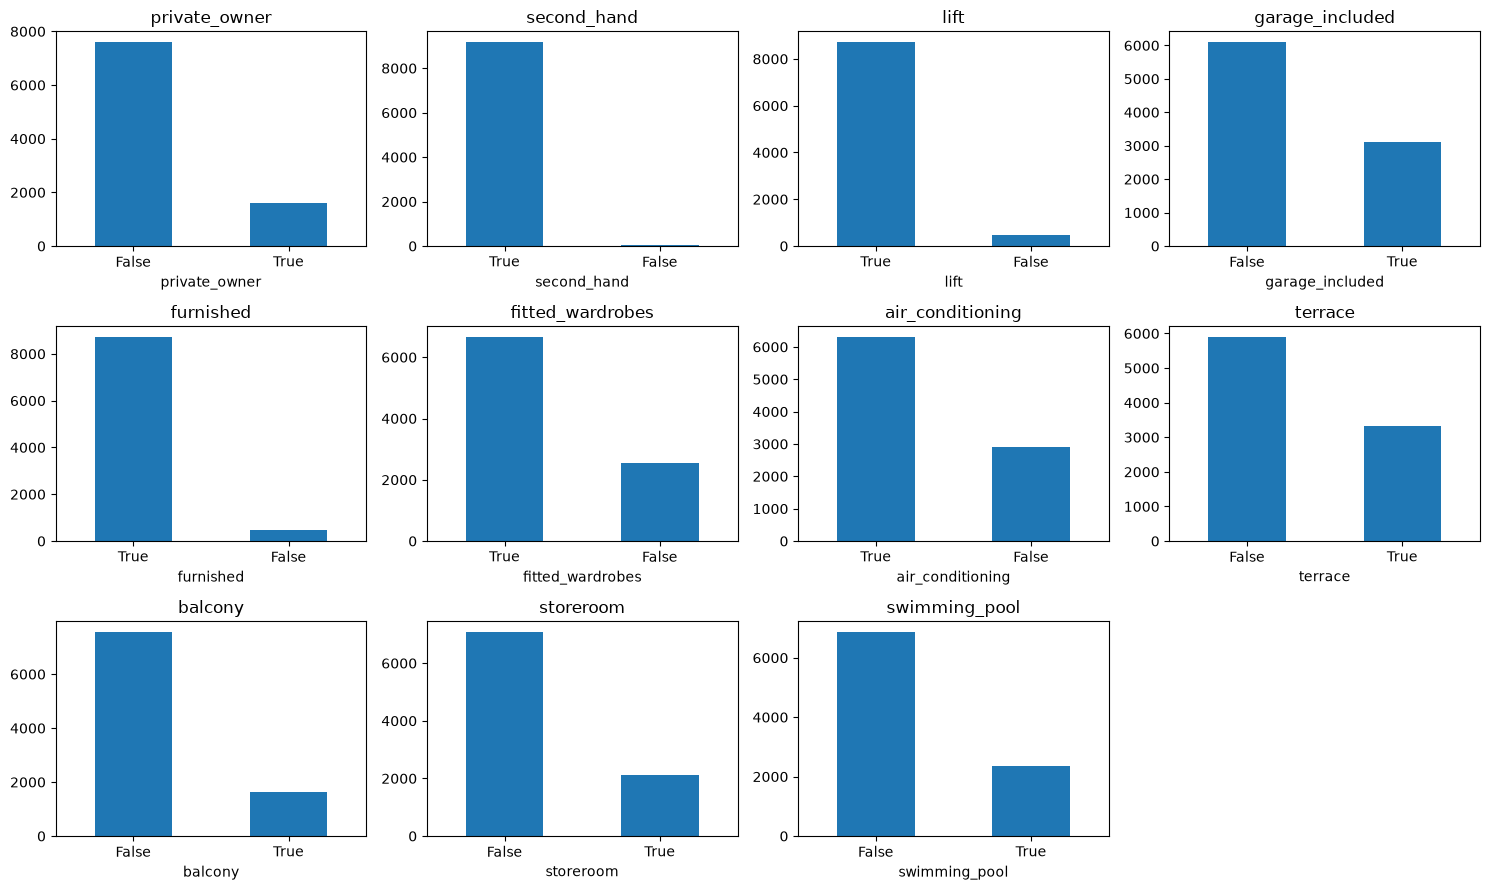

In [21]:
# dibujamos las columnas bool.
bool_cols = df_clean.select_dtypes(include=[bool]).columns.tolist()

fig, axes = plt.subplots(3, 4, figsize=(15, 9))
axes = axes.flatten()
for ax, col in zip(axes, bool_cols):
    df_clean[col].value_counts(dropna=False).plot.bar(ax=ax)
    ax.set_title(col)
    ax.tick_params(axis='x', rotation=0)

# ocultamos los subplots sobrantes (11 variables en un grid de 12).
for ax in axes[len(bool_cols):]:
    ax.set_visible(False)
plt.tight_layout()
plt.show()

- `second_hand` es casi constante (99,69% True).

- `swimming_pool` (25%) y `storeroom` (23%) tienen varianza razonable. De momento mantenemos todas las booleanas.


## 2. Análisis bivariante

Distribución de `price` según `fitted_wardrobes`.


In [22]:
# relación bivariante interactiva: fitted_wardrobes frente a price
df_fitted_wardrobes = df_clean[[
    "fitted_wardrobes", "price", "floor_built",
    "bedrooms", "bathrooms", "district",
]].copy()
df_fitted_wardrobes["armarios_empotrados"] = (
    df_fitted_wardrobes["fitted_wardrobes"]
    .map({False: "Sin armarios empotrados", True: "Con armarios empotrados"})
)

fig = px.box(
    df_fitted_wardrobes,
    x="armarios_empotrados",
    y="price",
    color="armarios_empotrados",
    points="all",
    log_y=True,
    category_orders={"armarios_empotrados": [
        "Sin armarios empotrados",
        "Con armarios empotrados",
    ]},
    labels={
        "armarios_empotrados": "Armarios empotrados",
        "price": "Precio del alquiler (€)",
    },
    hover_data={
        "armarios_empotrados": False,
        "fitted_wardrobes": True,
        "price": ":,.0f",
        "floor_built": ":,.0f",
        "bedrooms": True,
        "bathrooms": True,
        "district": True,
    },
    title="Precio según la presencia de armarios empotrados",
)
fig.update_traces(
    jitter=0.25,
    pointpos=0,
    marker={"size": 4, "opacity": 0.15},
)
fig.update_layout(
    xaxis_title="Armarios empotrados",
    yaxis_title="Precio",
    showlegend=False,
    height=600,
)
fig.show()

Mediana de alquiler: **1.200 €** sin armarios empotrados, **1.500 €** con ellos (+**25%** descriptivo). La distribución con armarios se desplaza hacia precios más altos, con cola larga.

No es causal: `fitted_wardrobes` va con viviendas más grandes y más amenities. Sirve como candidata; su aportación independiente se comprueba junto a `floor_built`, habitaciones, distrito y el resto.


## 3. Análisis multivariante

Comparamos booleanas entre sí: qué amenities suelen ir juntas y cómo se relacionan con `price`.


In [23]:
# relación multivariante interactiva: superficie, precio y armarios empotrados
df_wardrobes_surface_price = df_clean.loc[
    (df_clean["floor_built"] > 0) & (df_clean["price"] > 0),
    [
        "floor_built", "price", "fitted_wardrobes",
        "bedrooms", "bathrooms", "district",
    ],
].copy()
df_wardrobes_surface_price["armarios_empotrados"] = (
    df_wardrobes_surface_price["fitted_wardrobes"]
    .map({False: "Sin armarios empotrados", True: "Con armarios empotrados"})
)

fig = px.scatter(
    df_wardrobes_surface_price,
    x="floor_built",
    y="price",
    color="armarios_empotrados",
    log_x=True,
    log_y=True,
    opacity=0.45,
    color_discrete_map={
        "Sin armarios empotrados": "#636EFA",
        "Con armarios empotrados": "#EF553B",
    },
    labels={
        "floor_built": "Superficie construida (m2)",
        "price": "Precio del alquiler (€)",
        "armarios_empotrados": "Armarios empotrados",
    },
    hover_data={
        "fitted_wardrobes": True,
        "floor_built": ":,.0f",
        "price": ":,.0f",
        "bedrooms": True,
        "bathrooms": True,
        "district": True,
    },
    title="Superficie, precio y armarios empotrados - escala logarítmica",
)
fig.update_traces(marker={"size": 7})
fig.update_layout(
    xaxis_title="Superficie construida (m2)",
    yaxis_title="Precio en EUR",
    height=600,
)
fig.show()

Hay relación positiva entre `floor_built` y `price`: más m2, alquiler más alto. El color (`fitted_wardrobes`) muestra más armarios en superficies y precios altos, con mucho solape.

Los armarios empotrados marcan gama general, no explican el precio solos. Lectura descriptiva, junto a superficie, habitaciones y otras amenities.


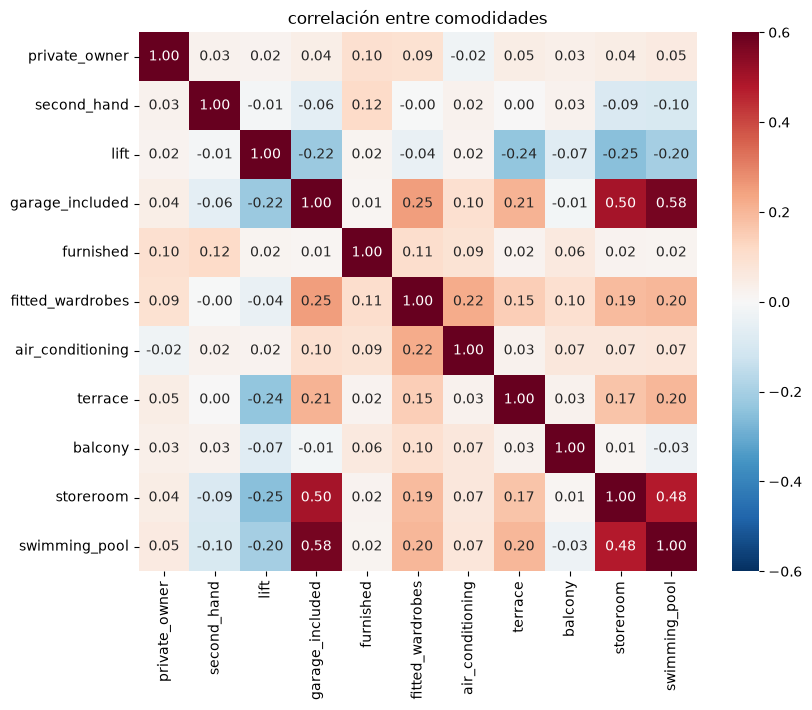

In [24]:
# matriz de correlación entre variables booleanas
bool_cols = [
    b for b in df_clean.select_dtypes(include=[bool]).columns
    if b not in ("equipped_kitchen", "garden_area")
]

corr_bool = df_clean[bool_cols].astype(int).corr()

plt.figure(figsize=(9, 7))
sns.heatmap(corr_bool, annot=True, fmt=".2f", cmap="RdBu_r",
            center=0, vmin=-0.6, vmax=0.6)
plt.title("correlación entre comodidades")
plt.show()

- Dos patrones: `storeroom` + `garage_included` + `swimming_pool` + `terrace` (urbanizaciones con servicios) frente a `lift`, que casi nunca va con ese pack.

- No son 13 señales independientes. En la práctica hay dos tipos de vivienda: `flat` (mayoría) y `otros`. Importa al elegir el modelo.


In [25]:
# señal de cada booleana con price: ¿sube o baja el precio cuando está presente?
resumen_bool_price = pd.DataFrame({
    "mediana_sin": [df_clean.loc[~df_clean[b], "price"].median() for b in bool_cols],
    "mediana_con": [df_clean.loc[df_clean[b], "price"].median() for b in bool_cols],
}, index=bool_cols)

resumen_bool_price["diferencia_%"] = (
    (resumen_bool_price["mediana_con"] / resumen_bool_price["mediana_sin"] - 1) * 100
).round(1)

resumen_bool_price.sort_values("diferencia_%", ascending=False)

,mediana_sin,mediana_con,diferencia_%
air_conditioning,1100.0,1650.0,50.0
balcony,1350.0,1850.0,37.0
fitted_wardrobes,1200.0,1500.0,25.0
furnished,1200.0,1425.0,18.8
terrace,1350.0,1600.0,18.5
garage_included,1350.0,1595.0,18.1
storeroom,1400.0,1595.0,13.9
second_hand,1240.0,1400.0,12.9
swimming_pool,1400.0,1500.0,7.1
private_owner,1500.0,1200.0,-20.0


- `air_conditioning`: la comodidad más ligada al precio. Mediana +**50%** con A/C.

- `lift` engaña: sin ascensor mediana 2.900 € frente a 1.400 € con ascensor. No abarata el ascensor: los caros (áticos, bajos de lujo) suelen estar en edificios sin él. Pista falsa típica; se confirma o cae en bivariante.

- `swimming_pool`: apenas mueve la mediana (+7%), pese a la intuición previa.


#### Estandarización

Para comparar variables en distintas escalas usamos **z-score**: restar media y dividir por desviación. Todas quedan en la misma escala.


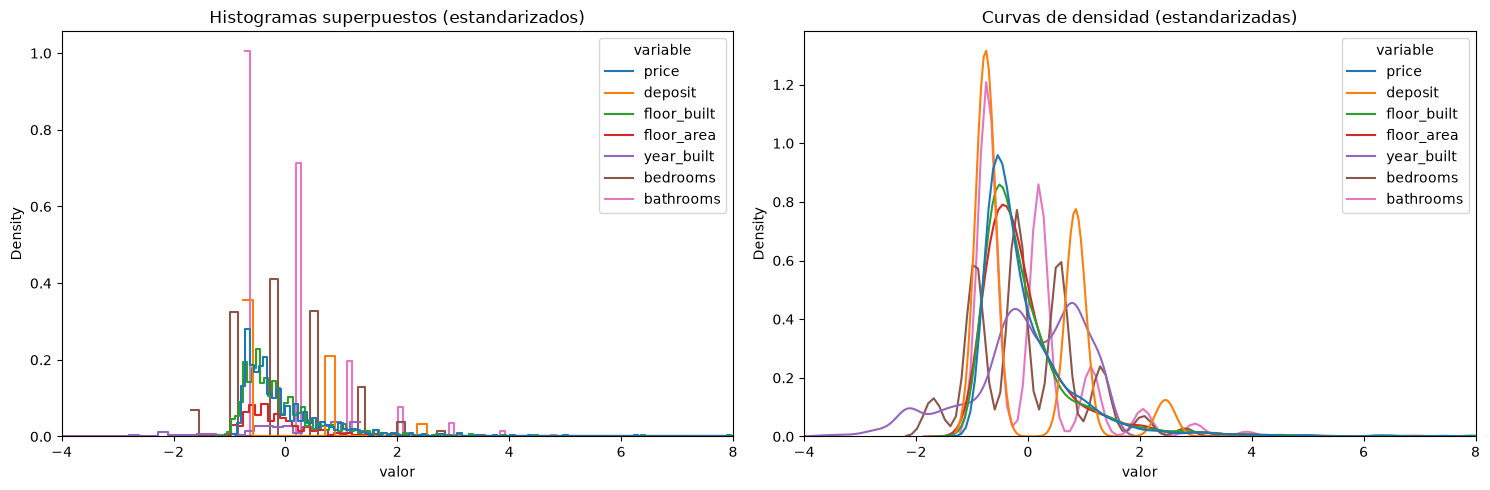

In [26]:
# copia estandarizada del df: solo numéricas, cada columna en unidades de z-score.
df_std = df_clean.select_dtypes(include=[np.number]).apply(
    lambda s: (s - s.mean()) / s.std()
)

df_std_long = df_std.melt(var_name="variable", value_name="valor")

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.histplot(data=df_std_long, x="valor", hue="variable", element="step",
             fill=False, stat="density", common_bins=False, ax=axes[0])
axes[0].set_title("Histogramas superpuestos (estandarizados)")
axes[0].set_xlim(-4, 8)

sns.kdeplot(data=df_std_long, x="valor", hue="variable", common_norm=False, ax=axes[1])
axes[1].set_title("Curvas de densidad (estandarizadas)")
axes[1].set_xlim(-4, 8)

plt.tight_layout()
plt.show()

**Lectura:**

- `price`, `floor_built` y `floor_area` comparten forma (campana + cola derecha). Van de la mano.

- `bedrooms` y `bathrooms`: campanas estrechas; mayoría en 1–3.

- `year_built`: más plana, con bultos por décadas.

- La forma compartida de precio y superficies respalda transformar el target al modelar.


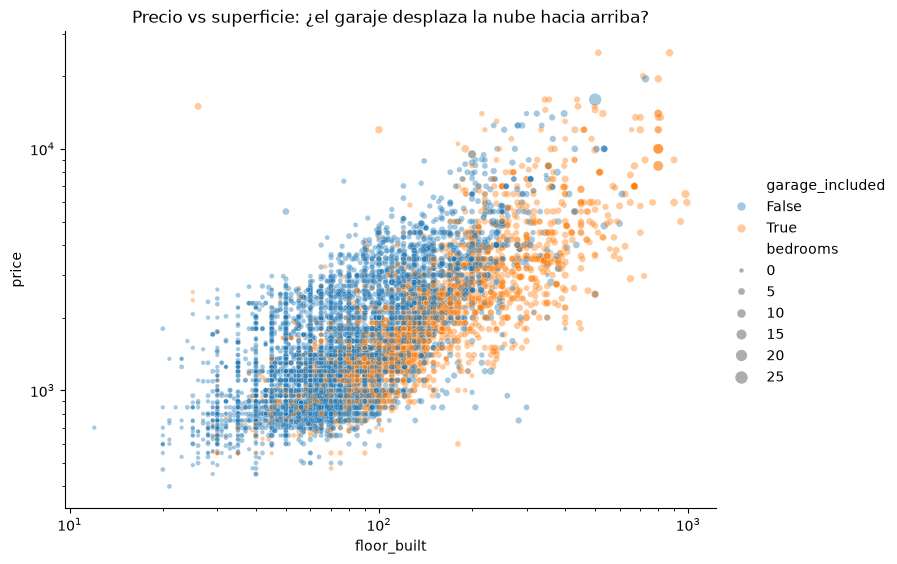

In [27]:
# superficie vs precio: color = garaje, tamaño = nº dormitorios.
sns.relplot(
    data=df_clean, x="floor_built", y="price",
    hue="garage_included", size="bedrooms",
    alpha=0.4, sizes=(10, 80), height=5.5, aspect=1.4,
)
plt.xscale("log")
plt.yscale("log")
plt.title("Precio vs superficie: ¿el garaje desplaza la nube hacia arriba?")
plt.show()

Con `seaborn.relplot`: `hue` = color, `size` = tamaño del punto.

- Superficie–precio: a más m2, más precio (nube en diagonal).

- El garaje **no** desplaza la nube: a igual tamaño hay puntos con y sin garaje a la misma altura. El +18% de mediana previo viene de que el garaje aparece más en pisos grandes, no de un efecto aislado.


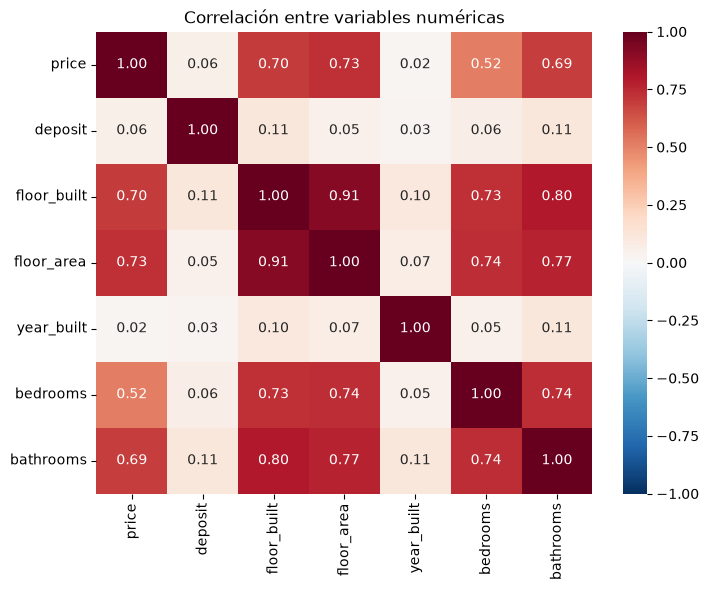

In [28]:
# matriz de correlación de las numéricas.
corr_num = df_clean[num_cols].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr_num, annot=True, fmt=".2f", cmap="RdBu_r",
            center=0, vmin=-1, vmax=1)
plt.title("Correlación entre variables numéricas")
plt.show()

- Con `price` correlacionan las de **tamaño**: `floor_area` (0,73), `floor_built` (0,70), `bathrooms` (0,69), `bedrooms` (0,52).

- `floor_built` y `floor_area` entre sí: 0,91 (casi lo mismo; `floor_area` tiene 57% nulos). Candidatas a quedarnos con una.

- `year_built` y `deposit` ~0,06 con casi todo: poca señal lineal sola.

- Tamaño entre sí: 0,73–0,91. En un modelo lineal hay que vigilar colinealidad.


### Relación precio–superficie: `price`, `floor_area` y `floor_built`

Tres columnas y sus correlaciones para ver qué aporta al target.


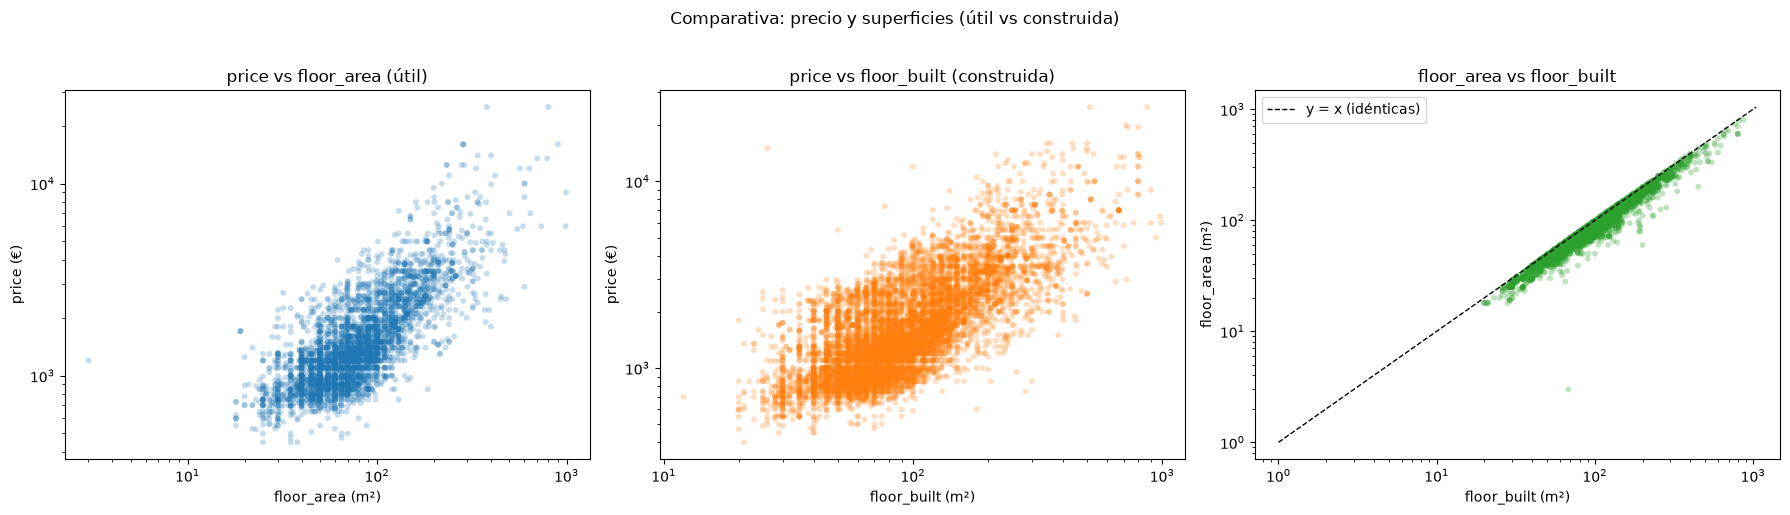

In [29]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.scatterplot(
    data=df_clean, x="floor_area", y="price",
    alpha=0.25, s=18, edgecolor="none", color="tab:blue", ax=axes[0]
)
axes[0].set_xscale("log")
axes[0].set_yscale("log")
axes[0].set_title("price vs floor_area (útil)")
axes[0].set_xlabel("floor_area (m²)")
axes[0].set_ylabel("price (€)")

sns.scatterplot(
    data=df_clean, x="floor_built", y="price",
    alpha=0.25, s=18, edgecolor="none", color="tab:orange", ax=axes[1]
)
axes[1].set_xscale("log")
axes[1].set_yscale("log")
axes[1].set_title("price vs floor_built (construida)")
axes[1].set_xlabel("floor_built (m²)")
axes[1].set_ylabel("price (€)")

sns.scatterplot(
    data=df_clean, x="floor_built", y="floor_area",
    alpha=0.3, s=18, edgecolor="none", color="tab:green", ax=axes[2]
)
lims = [1, max(df_clean["floor_built"].max(), df_clean["floor_area"].max()) * 1.05]
axes[2].plot(lims, lims, ls="--", c="black", lw=1, label="y = x (idénticas)")
axes[2].set_xscale("log")
axes[2].set_yscale("log")
axes[2].set_title("floor_area vs floor_built")
axes[2].set_xlabel("floor_built (m²)")
axes[2].set_ylabel("floor_area (m²)")
axes[2].legend(loc="upper left")

plt.suptitle("Comparativa: precio y superficies (útil vs construida)", y=1.02)
plt.tight_layout()
plt.show()

La búsqueda de hiperparámetros va más adelante, tras `df_model` y el preprocesador.

`RandomizedSearchCV` reutiliza el mismo split y la misma validación cruzada que la comparación base.


- **Azul y naranja:** la nube precio–superficie tiene la misma forma con `floor_area` o `floor_built`. Casi equivalentes para explicar precio; cambia la cobertura (`floor_area` solo en el 43% de registros).

- **Verde:** la línea discontinua es `y = x`. **Todos los puntos quedan por debajo:** `floor_built` ≥ `floor_area` de forma sistemática (mediana ~10 m2 de separación, media ~14 m2). Esperable: construida incluye muros, balcones y comunes.

- **Para el modelo:** información redundante (colinealidad 0,91). Nos quedamos con `floor_built` (cero nulos, más cobertura) y descartamos `floor_area`, o como mucho el flag de ausencia.


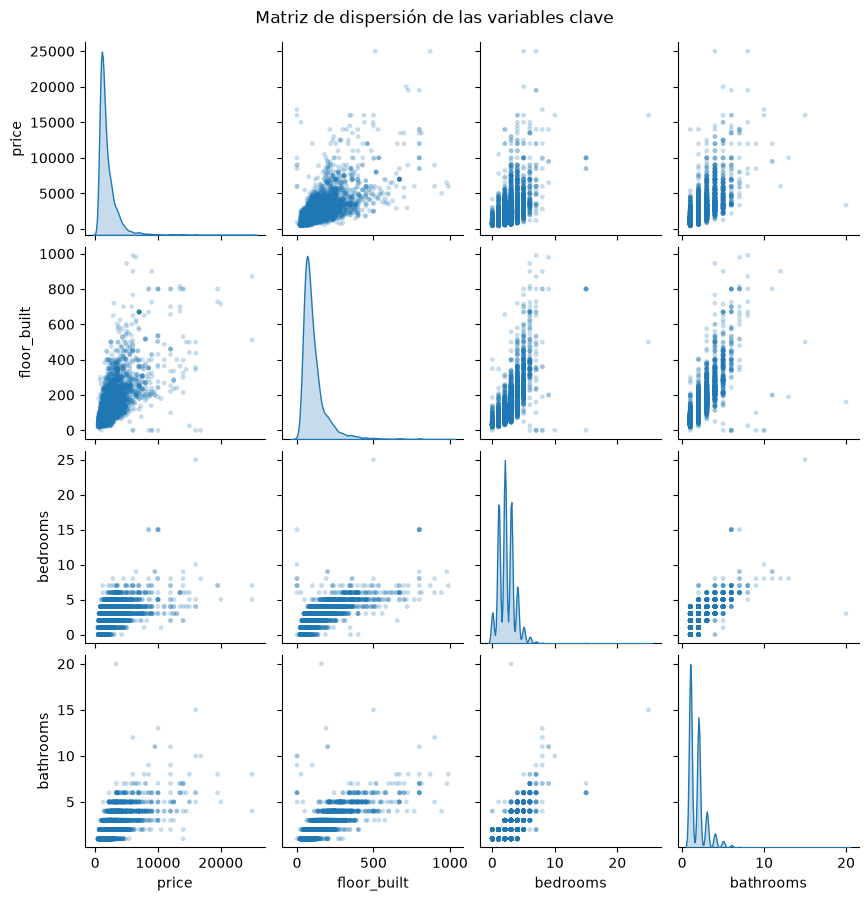

In [30]:
# matriz de dispersión: combinaciones posibles entre las 4 más relevantes.
vars_clave = ["price", "floor_built", "bedrooms", "bathrooms"]

sns.pairplot(df_clean[vars_clave], diag_kind="kde",
             plot_kws={"alpha": 0.25, "s": 12, "edgecolor": "none"},
             height=2.2)
plt.suptitle("Matriz de dispersión de las variables clave", y=1.02)
plt.show()

In [31]:
df_clean.head().T

,0,1,2,3,4
type,Flat,Penthouse,Duplex,Flat,Studio
price,1400.0,1300.0,950.0,2975.0,650.0
deposit,<NA>,1,1,1,1
private_owner,False,False,False,False,False
floor_built,60,77,72,160,30
floor_area,NaN,NaN,68.0,NaN,NaN
floor,3rd,6th,3rd,3rd,4th
year_built,1954,1961,1999,<NA>,<NA>
orientation,<NA>,<NA>,east,west,<NA>
bedrooms,2,2,1,4,0


In [32]:
df_clean.info()

<class 'pandas.DataFrame'>
RangeIndex: 9229 entries, 0 to 9228
Data columns (total 26 columns):
 #   Column            Non-Null Count  Dtype   
---  ------            --------------  -----   
 0   type              9229 non-null   category
 1   price             9229 non-null   float64 
 2   deposit           5407 non-null   Int64   
 3   private_owner     9229 non-null   bool    
 4   floor_built       9229 non-null   int64   
 5   floor_area        3938 non-null   float64 
 6   floor             8908 non-null   str     
 7   year_built        2893 non-null   Int64   
 8   orientation       4411 non-null   category
 9   bedrooms          9229 non-null   int64   
 10  bathrooms         9229 non-null   int64   
 11  second_hand       9229 non-null   bool    
 12  lift              9229 non-null   bool    
 13  garage_included   9229 non-null   bool    
 14  furnished         9229 non-null   bool    
 15  fitted_wardrobes  9229 non-null   bool    
 16  air_conditioning  9229 non-null   b

Tras tipar y limpiar lo básico tenemos un dataframe más usable. Aún no hemos cerrado la preparación de training.


## 3. Conclusiones del EDA

1. **Tamaño mueve el precio:** `floor_built` (0,70), `floor_area` (0,73), `bathrooms` (0,69), `bedrooms` (0,52). Dominante: superficie construida.

2. **`floor_built` vs `floor_area`:** correlación 0,91 y misma pendiente con precio. `floor_area` solo en el 43%. Nos quedamos con `floor_built`.

3. **`floor` está sucia:** ~81% ordinales (`1st`…`30th`), ~13% especiales (`ground`…), resto m2 colados u errores. **Preparación:** numérica ordinal 0…30; m2 colados → nulo.

4. **`price` asimétrica:** cola a la derecha (hasta ~25.000 €). **Yeo-Johnson** sobre el target en train; métricas en euros con la inversa.

5. **Amenities:** `air_conditioning` ~+50% en mediana. `lift` al revés (sin ascensor → más caro: casas/áticos). `second_hand` casi constante (99,7%); poco aporta.

6. **Ubicación:** `district` / `subdistrict` / `postalcode` segmentan; one-hot cuidando cardinalidad.

7. **Fuera del modelado:** `web_id`, `url`, `title`, `professional_name`, `equipped_kitchen`, `garden_area`. En preparación caen también `location`, `last_update` y `floor_area`.

8. **`type`:** agrupamos rarezas en `otros` frente a la dominancia de `Flat`.

Siguiente: preparación y modelado (regresión sobre `price`, clasificación sobre `balcony`).


# Preparación de datos para training

1. **Saneamiento:** `floor_built` ≤ 0 → nulo; `floor` → ordinal numérica.

2. **Ingeniería ligera:** `rooms_total`, `amenities_count`.

3. **Encoding** de categóricas (`type`, `orientation`, `district`, `subdistrict`, `postalcode`, …).

4. **Escalado** de numéricas con `StandardScaler`.

5. **Yeo-Johnson** sobre `price` (solo train).

6. **Split** 80/20 sin fuga: imputer, scaler y transform del target se ajustan solo en train.


In [33]:
# dataset de modelado a partir de df_clean
df_model = df_clean.drop(
    columns=["location", "last_update", "floor_area", "professional_name"],
    errors="ignore",
).copy()

# deposit: la ausencia es informativa; no es un valor numérico desconocido que debamos inventar.
df_model["deposit_missing"] = df_model["deposit"].isna().astype("int8")
df_model["deposit"] = (
    df_model["deposit"]
    .astype("Int64")
    .astype("string")
    .fillna("no_informado")
    .astype("object")
)
assert df_model["deposit_missing"].sum() == df_clean["deposit"].isna().sum()
assert df_model["deposit"].isna().sum() == 0


# anomalías de superficie construida
df_model.loc[df_model["floor_built"] <= 0, "floor_built"] = np.nan

# limpieza de floor -> numérica ordinal
def limpiar_floor(val, floor_built):
    if pd.isna(val):
        return np.nan

    s = str(val).strip().lower()
    if s in {"", "nan", "none", "<na>"}:
        return np.nan

    # conservamos la semántica de las plantas especiales; no inventamos altura.
    if s in {"ground", "bajo", "bj"}:
        return 0
    if s in {"basement", "sotano", "sótano", "ss", "st"}:
        return -1
    if s in {"semi-basement", "semibasement", "semisotano", "semisótano"}:
        return -0.5
    if s in {"ent", "entreplanta", "entresuelo"}:
        return 0.5
    if s in {"top", "atico", "ático", "attic"}:
        return np.nan

    # ordinal explícito es la fuente fiable para una planta numérica.
    ordinal = re.fullmatch(r"(\d+)(?:st|nd|rd|th)", s)
    if ordinal:
        num = int(ordinal.group(1))
        return num if 1 <= num <= 30 else np.nan

    # Los enteros sin sufijo pueden ser m2 colados: se contrastan con floor_built.
    if re.fullmatch(r"\d+", s):
        num = int(s)
        if 0 <= num <= 30 and (pd.isna(floor_built) or num != floor_built):
            return num

    return np.nan

df_model["floor"] = (
    df_model.apply(
        lambda row: limpiar_floor(row["floor"], row["floor_built"]),
        axis=1,
    ).astype("Int64")
)

# agrupamos los tipos residuales antes del one-hot encoding.
tipos_residuales = {"house", "estate", "village"}
df_model["type"] = (
    df_model["type"]
    .astype("string")
    .str.strip()
    .mask(lambda valores: valores.str.lower().isin(tipos_residuales), "otros")
)

# feature engineering: creamos una nueva variable que sume dormitorios y baños.
df_model["rooms_total"] = df_model["bedrooms"] + df_model["bathrooms"]

amenities = [
    "lift", "garage_included", "furnished", "fitted_wardrobes",
    "air_conditioning", "terrace", "storeroom", "swimming_pool",
]
for c in amenities + ["second_hand", "private_owner", "balcony"]:
    df_model[c] = df_model[c].astype(int)

df_model["amenities_count"] = df_model[amenities].sum(axis=1)

# Ausencias categóricas: solo los registros no informados usan una etiqueta explícita.
categoria_desconocida = "desconocido"
columnas_categoricas_modelo = [
    "type", "orientation", "district", "subdistrict", "postalcode", "deposit",
]
columnas_categoricas_con_ausencia = [
    "orientation", "district", "subdistrict", "postalcode",
]

for c in columnas_categoricas_modelo:
    valores = df_model[c].astype("string")
    if c in columnas_categoricas_con_ausencia:
        valores = valores.fillna(categoria_desconocida)
    df_model[c] = valores.astype("object")

assert str(df_model["year_built"].dtype) == "Int64"
assert str(df_model["deposit"].dtype) == "object"
assert str(df_model["deposit_missing"].dtype) == "int8"
assert "no_informado" in df_model["deposit"].unique()
for c in columnas_categoricas_con_ausencia:
    assert df_model[c].isna().sum() == 0

print(f"df_model: {df_model.shape[0]} filas × {df_model.shape[1]} columnas")
print(f"nulos restantes:\n{df_model.isna().sum()[df_model.isna().sum() > 0]}")
df_model.head().T


df_model: 9229 filas × 26 columnas
nulos restantes:
floor_built       9
floor           672
year_built     6336
dtype: int64


,0,1,2,3,4
type,Flat,Penthouse,Duplex,Flat,Studio
price,1400.0,1300.0,950.0,2975.0,650.0
deposit,no_informado,1,1,1,1
private_owner,0,0,0,0,0
floor_built,60.0,77.0,72.0,160.0,30.0
floor,3,6,3,3,4
year_built,1954,1961,1999,<NA>,<NA>
orientation,desconocido,desconocido,east,west,desconocido
bedrooms,2,2,1,4,0
bathrooms,1,2,1,3,1


Tras la preparación, el dataframe queda listo para training.

Ejemplos:

- `air_conditioning` (y `swimming_pool`): de `bool` a 0/1.

- `postalcode`: nulos como `'desconocido'`; valores válidos como `str` legible. Igual patrón en `orientation`. Con baja cardinalidad, `orientation` no exige un encoding aparte más allá del one-hot del pipeline.


In [34]:
df_model.info()

<class 'pandas.DataFrame'>
RangeIndex: 9229 entries, 0 to 9228
Data columns (total 26 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   type              9229 non-null   object 
 1   price             9229 non-null   float64
 2   deposit           9229 non-null   object 
 3   private_owner     9229 non-null   int64  
 4   floor_built       9220 non-null   float64
 5   floor             8557 non-null   Int64  
 6   year_built        2893 non-null   Int64  
 7   orientation       9229 non-null   object 
 8   bedrooms          9229 non-null   int64  
 9   bathrooms         9229 non-null   int64  
 10  second_hand       9229 non-null   int64  
 11  lift              9229 non-null   int64  
 12  garage_included   9229 non-null   int64  
 13  furnished         9229 non-null   int64  
 14  fitted_wardrobes  9229 non-null   int64  
 15  air_conditioning  9229 non-null   int64  
 16  terrace           9229 non-null   int64  
 17  balcon

# Fase de modelado

Con **Scikit-learn**:

| Sub-tarea | Target | Tipo | Métricas |
|---|---|---|---|
| A | `price` | Regresión | MSE, RMSE, MAE en €; R2 |
| B | `balcony` | Clasificación binaria | accuracy, F1, matriz de confusión |

**Target de regresión:** `PowerTransformer(method="yeo-johnson")` solo sobre `y_train`. Entrenamos en escala transformada y reportamos errores en euros con `inverse_transform`.

**`deposit`:** meses de fianza con orden; ausencia sin mediana ni `0`. `deposit_missing` + categoría `no_informado` en one-hot.

**Flujo:** baseline con `floor_built` → tres algoritmos. Preproceso (`make_column_selector` + `make_column_transformer`) dentro del pipeline para no filtrar test a train.


In [35]:
# regresión: preparamos X e y, y se transforma con Yeo-Johnson para aproximar la normalidad.
X_reg = df_model.drop(columns=["price"])
y_reg = df_model["price"].astype(float)

# deposit es categoría explícita; solo deposit_missing representa numéricamente su ausencia.
assert "deposit_missing" in X_reg.columns
assert X_reg["deposit"].dtype == object
assert "deposit" not in X_reg.select_dtypes(include=np.number).columns

X_train, X_test, y_train, y_test = train_test_split(
    X_reg, y_reg, test_size=0.2, random_state=42
)

# preprocesador: numéricas (imputer + scaler) y categóricas (one-hot)
num_pipeline = make_pipeline(
    SimpleImputer(strategy="median"),
    StandardScaler(),
)
cat_pipeline = make_pipeline(
    SimpleImputer(strategy="constant", fill_value=categoria_desconocida),
    OneHotEncoder(handle_unknown="ignore", sparse_output=False),
)

preprocessor = make_column_transformer(
    (num_pipeline, make_column_selector(dtype_include=np.number)),
    (cat_pipeline, make_column_selector(dtype_include=object)),
)

# Yeo-Johnson del target: se ajusta SOLO con y_train
pt_y = PowerTransformer(method="yeo-johnson")
y_train_t = pt_y.fit_transform(y_train.to_numpy().reshape(-1, 1)).ravel()

# helper: devuelve predicciones transformadas de vuelta a euros, recortando a los límites del target original.
def a_euros(pred_t):
    pred_t = np.clip(np.asarray(pred_t, dtype=float), y_train_t.min(), y_train_t.max())
    return pt_y.inverse_transform(pred_t.reshape(-1, 1)).ravel()

print(f"Train: {X_train.shape[0]} | Test: {X_test.shape[0]}")
print(f"price train — media: {y_train.mean():.0f} € | skew {y_train.skew():.2f}")
print(f"price train (Yeo-Johnson) — media: {y_train_t.mean():.3f} | skew {pd.Series(y_train_t).skew():.2f}")


Train: 7383 | Test: 1846
price train — media: 1946 € | skew 4.26
price train (Yeo-Johnson) — media: 0.000 | skew 0.06


`price` original: cola alta (skew=4,26). Yeo-Johnson baja la asimetría (skew=0,06) y centra alrededor de cero. Facilita algunos modelos; la calidad real se mide en euros.


In [36]:
# baseline univariable: solo floor_built, target en euros (comprobar que el flujo funciona)
pipe_base = make_pipeline(
    make_column_transformer(
        (make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), ["floor_built"])
    ),
    LinearRegression(),
)

cv_base = cross_validate(
    pipe_base, X_train, y_train, cv=5,
    scoring=["r2", "neg_root_mean_squared_error", "neg_mean_absolute_error"],
)
pipe_base.fit(X_train, y_train)
y_pred_base = pipe_base.predict(X_test)

print("BASELINE (solo floor_built, sin Yeo-Johnson)")
print(
    f"Capacidad explicativa en cross_validation: {cv_base['test_r2'].mean() * 100:.1f} % "
    f"(± {cv_base['test_r2'].std() * 100:.1f} %)"
)
print(f"Capacidad explicativa en test: {r2_score(y_test, y_pred_base) * 100:.1f} %")
print(f"Error medio por anuncio: {mean_absolute_error(y_test, y_pred_base):.2f} €")
print(f"Error típico, penalizando fallos grandes: {root_mean_squared_error(y_test, y_pred_base):.2f} €")

BASELINE (solo floor_built, sin Yeo-Johnson)
Capacidad explicativa en cross_validation: 48.3 % (± 4.9 %)
Capacidad explicativa en test: 52.0 %
Error medio por anuncio: 641.31 €
Error típico, penalizando fallos grandes: 1033.96 €


Empezamos con un baseline de una variable. Si el multivariable mejora mucho en train y poco en test, hay sobreajuste.

Si añadir variables apenas mejora, la primera ya domina el target.

La validación cruzada da una estimación más estable que un solo split y muestra si el resultado depende de una partición concreta.


In [37]:
# comparativa multivariable: 3 regresores
reg_models = {
    "LinearRegression": LinearRegression(),
    "KNeighborsRegressor": KNeighborsRegressor(n_neighbors=7),
    "RandomForestRegressor": RandomForestRegressor(
        n_estimators=120, max_depth=16, random_state=42, n_jobs=-1
    ),
}

kf = KFold(n_splits=5, shuffle=True, random_state=42)
reg_rows = []
reg_fitted = {}

for name, model in reg_models.items():
    pipe = make_pipeline(clone(preprocessor), model)
    cv = cross_validate(
        pipe, X_train, y_train_t, cv=kf,
        scoring=["r2", "neg_root_mean_squared_error", "neg_mean_absolute_error"],
    )
    pipe.fit(X_train, y_train_t)
    reg_fitted[name] = pipe

    y_pred_eur = a_euros(pipe.predict(X_test))

    reg_rows.append({
        "Modelo": name,
        "R2 CV (target transformado) (%)": cv["test_r2"].mean() * 100,
        "R2 test (%)": r2_score(y_test, y_pred_eur) * 100,
        "MAE (€)": mean_absolute_error(y_test, y_pred_eur),
        "RMSE (€)": root_mean_squared_error(y_test, y_pred_eur),
    })

df_reg = (
    pd.DataFrame(reg_rows)
    .sort_values("R2 test (%)", ascending=False)
    .reset_index(drop=True)
)

for _, row in df_reg.iterrows():
    print(
        f"{row['Modelo']}: explica {row['R2 test (%)']:.1f} % de la variabilidad del precio; "
        f"se desvía, de media, {row['MAE (€)']:.0f} € por anuncio. "
        f"El RMSE, sensible a los errores grandes, es "
        f"{row['RMSE (€)']:.0f} €."
    )

df_reg


RandomForestRegressor: explica 83.4 % de la variabilidad del precio; se desvía, de media, 332 € por anuncio. El RMSE, sensible a los errores grandes, es 607 €.
KNeighborsRegressor: explica 63.6 % de la variabilidad del precio; se desvía, de media, 481 € por anuncio. El RMSE, sensible a los errores grandes, es 900 €.
LinearRegression: explica 25.2 % de la variabilidad del precio; se desvía, de media, 472 € por anuncio. El RMSE, sensible a los errores grandes, es 1290 €.


,Modelo,R2 CV (target transformado) (%),R2 test (%),MAE (€),RMSE (€)
0,RandomForestRegressor,81.655281,83.442635,331.638602,607.209692
1,KNeighborsRegressor,66.273400,63.613342,481.246934,900.148513
2,LinearRegression,75.805426,25.249002,472.204238,1290.183788


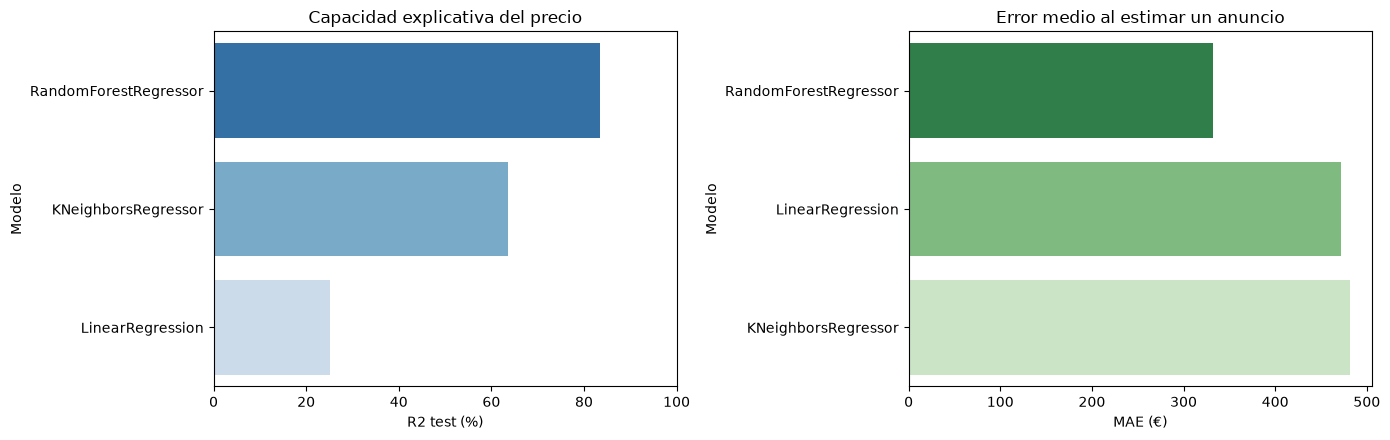

In [38]:
# visualización comparativa de regresión
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

sns.barplot(
    data=df_reg, x="R2 test (%)", y="Modelo", ax=axes[0],
    hue="Modelo", legend=False, palette="Blues_r",
)
axes[0].set_xlim(0, 100)
axes[0].set_title("Capacidad explicativa del precio")

sns.barplot(
    data=df_reg.sort_values("MAE (€)"), x="MAE (€)", y="Modelo",
    ax=axes[1], hue="Modelo", legend=False, palette="Greens_r",
)
axes[1].set_title("Error medio al estimar un anuncio")

plt.tight_layout()
plt.show()


En el mismo test, **RandomForestRegressor** lidera: mayor R2 y menores MAE y RMSE. MAE = error medio en euros; RMSE penaliza más los errores grandes. Conclusión de esta partición; conviene contrastar con CV.


Mejor modelo: RandomForestRegressor
R2:   0.8344
MSE:  368703.61
RMSE: 607.21 €
MAE:  331.64 €


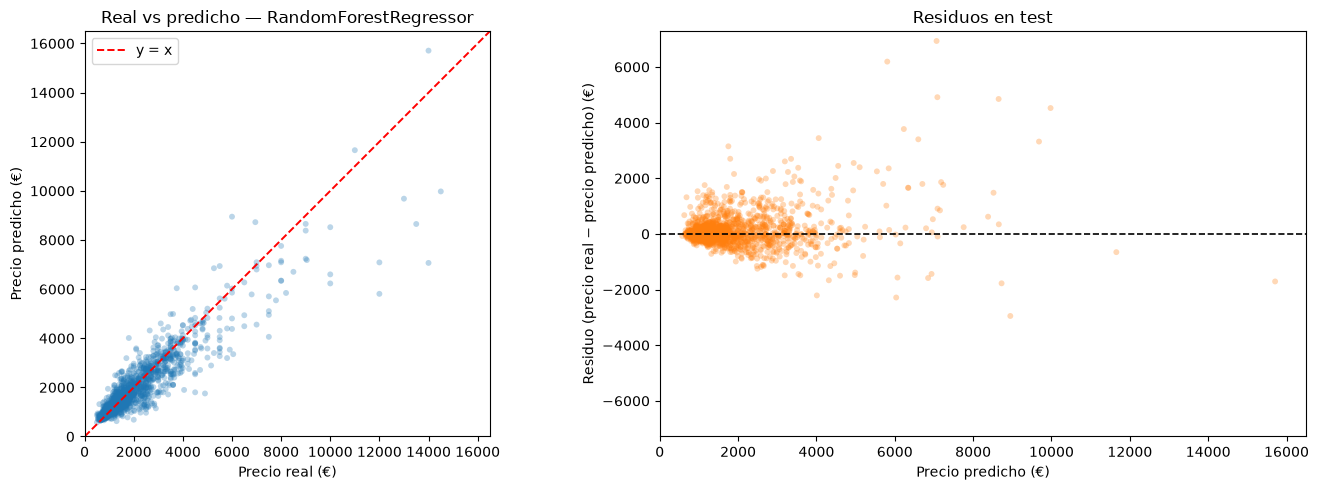

In [39]:
# evaluación del mejor regresor en test
best_reg_name = df_reg.iloc[0]["Modelo"]
best_reg = reg_fitted[best_reg_name]
y_pred_best = a_euros(best_reg.predict(X_test))

print(f"Mejor modelo: {best_reg_name}")
print(f"R2:   {r2_score(y_test, y_pred_best):.4f}")
print(f"MSE:  {mean_squared_error(y_test, y_pred_best):.2f}")
print(f"RMSE: {root_mean_squared_error(y_test, y_pred_best):.2f} €")
print(f"MAE:  {mean_absolute_error(y_test, y_pred_best):.2f} €")

y_test_values = y_test.to_numpy(dtype=float)
residuos = y_test_values - y_pred_best

# límites dinámicos: la figura muestra todo el rango evaluado.
limite_precio = max(y_test_values.max(), np.asarray(y_pred_best).max()) * 1.05
limite_predicho = np.asarray(y_pred_best).max() * 1.05
limite_residuo = np.abs(residuos).max() * 1.05

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].scatter(y_test, y_pred_best, alpha=0.3, s=18, edgecolor="none")
axes[0].plot([0, limite_precio], [0, limite_precio], "r--", lw=1.4, label="y = x")
axes[0].set_xlim(0, limite_precio)
axes[0].set_ylim(0, limite_precio)
axes[0].set_aspect("equal", adjustable="box")
axes[0].set_xlabel("Precio real (€)")
axes[0].set_ylabel("Precio predicho (€)")
axes[0].set_title(f"Real vs predicho — {best_reg_name}")
axes[0].legend()

axes[1].scatter(y_pred_best, residuos, alpha=0.3, s=18, color="tab:orange", edgecolor="none")
axes[1].axhline(0, color="black", ls="--", lw=1.2)
axes[1].set_xlim(0, limite_predicho)
axes[1].set_ylim(-limite_residuo, limite_residuo)
axes[1].set_xlabel("Precio predicho (€)")
axes[1].set_ylabel("Residuo (precio real − precio predicho) (€)")
axes[1].set_title("Residuos en test")

plt.tight_layout()
plt.show()


In [40]:
# optimización de hiperparámetros con RandomizedSearchCV sobre el modelo ganador
pipe_rf_search = Pipeline([
    ("preprocess", clone(preprocessor)),
    ("model", RandomForestRegressor(random_state=42, n_jobs=-1))
])

param_dist = {
    "model__n_estimators": [100, 150, 200, 250],
    "model__max_depth": [10, 14, 18, 22, None],
    "model__min_samples_split": [2, 5, 8],
    "model__min_samples_leaf": [1, 2, 4],
    "model__max_features": ["sqrt", 0.7, 0.8, 1.0]
}

search_rf = RandomizedSearchCV(
    pipe_rf_search,
    param_distributions=param_dist,
    n_iter=15,
    cv=kf,
    scoring="r2",
    random_state=42,
    n_jobs=-1
)
search_rf.fit(X_train, y_train_t)

y_pred_rf_opt = a_euros(search_rf.best_estimator_.predict(X_test))

print(f"Mejores hiperparámetros: {search_rf.best_params_}")
print(f"R2 CV optimizado (target transformado): {search_rf.best_score_ * 100:.2f} %")
print(f"R2 test optimizado: {r2_score(y_test, y_pred_rf_opt) * 100:.2f} %")
print(f"MAE test: {mean_absolute_error(y_test, y_pred_rf_opt):.2f} €")
print(f"RMSE test: {root_mean_squared_error(y_test, y_pred_rf_opt):.2f} €")

# comparativa: baseline vs optimizado
df_tuning_comp = pd.DataFrame([
    {
        "Modelo": "RandomForestRegressor (Base)",
        "R2 test (%)": df_reg.loc[df_reg["Modelo"] == "RandomForestRegressor", "R2 test (%)"].values[0],
        "MAE (€)": df_reg.loc[df_reg["Modelo"] == "RandomForestRegressor", "MAE (€)"].values[0],
        "RMSE (€)": df_reg.loc[df_reg["Modelo"] == "RandomForestRegressor", "RMSE (€)"].values[0],
    },
    {
        "Modelo": "RandomForestRegressor (Optimizado)",
        "R2 test (%)": r2_score(y_test, y_pred_rf_opt) * 100,
        "MAE (€)": mean_absolute_error(y_test, y_pred_rf_opt),
        "RMSE (€)": root_mean_squared_error(y_test, y_pred_rf_opt),
    }
])
display(df_tuning_comp.round(2))

Mejores hiperparámetros: {'model__n_estimators': 200, 'model__min_samples_split': 8, 'model__min_samples_leaf': 2, 'model__max_features': 1.0, 'model__max_depth': None}
R2 CV optimizado (target transformado): 82.21 %
R2 test optimizado: 82.59 %
MAE test: 327.65 €
RMSE test: 622.73 €


,Modelo,R2 test (%),MAE (€),RMSE (€)
0,RandomForestRegressor (Base),83.44,331.64,607.21
1,RandomForestRegressor (Optimizado),82.59,327.65,622.73


**Azul (predicho vs real):**
Sigue la diagonal: al subir el precio real, suben las predicciones.
La dispersión crece en precios altos. Muchos caros quedan bajo la línea roja: el modelo subestima parte de la gama alta.

También hay regresión a la media: puede sobrestimar baratos y subestimar caros.

**Naranja (residuos):**
Concentrados cerca de cero, con más dispersión en lo caro (menos muestras).

Más errores positivos grandes que negativos: refuerza la subestimación en precios altos.


## Comparativa adicional: Random Forest vs red neuronal

Red sencilla TensorFlow-Keras frente a `RandomForestRegressor`. Misma features, mismo split, mismo Yeo-Johnson y mismas métricas en euros.

Arquitectura: dos capas ocultas (`256 -> 128`), Adam, `EarlyStopping`. Validación dentro de train; test solo al final.


In [41]:
# comparativa adicional: RandomForestRegressor vs red neuronal Keras
import tensorflow as tf

# Semilla para hacer reproducible el entrenamiento de la red.
tf.keras.utils.set_random_seed(42)
tf.keras.backend.clear_session()

# Validación interna: el test exterior sigue sin tocarse durante el entrenamiento.
X_nn_fit, X_nn_val, y_nn_fit, y_nn_val = train_test_split(
    X_train, y_train_t, test_size=0.2, random_state=42
)

# Preprocesador independiente: se ajusta solo con la parte usada para entrenar la red.
preprocessor_nn = clone(preprocessor)
X_nn_fit_t = preprocessor_nn.fit_transform(X_nn_fit)
X_nn_val_t = preprocessor_nn.transform(X_nn_val)
X_test_nn = preprocessor_nn.transform(X_test)

nn_model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(X_nn_fit_t.shape[1],)),
    tf.keras.layers.Dense(256, activation="relu"),
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dense(1),
])

nn_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=3e-4),
    loss="mse",
)

callbacks_nn = [
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=10,
        min_lr=1e-5,
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=40,
        restore_best_weights=True,
    ),
]


history_nn = nn_model.fit(
    X_nn_fit_t,
    y_nn_fit,
    validation_data=(X_nn_val_t, y_nn_val),
    epochs=400,
    batch_size=32,
    callbacks=callbacks_nn,
    verbose=1,
    shuffle=True,
)

# Las métricas se expresan en euros, después de invertir Yeo-Johnson.
y_pred_nn = a_euros(nn_model.predict(X_test_nn, verbose=1).ravel())

rf_row = df_reg.loc[
    df_reg["Modelo"] == "RandomForestRegressor",
    ["Modelo", "R2 test (%)", "MAE (€)", "RMSE (€)"],
].copy()
nn_row = pd.DataFrame(
    [
        {
            "Modelo": "KerasRegressor",
            "R2 test (%)": r2_score(y_test, y_pred_nn) * 100,
            "MAE (€)": mean_absolute_error(y_test, y_pred_nn),
            "RMSE (€)": root_mean_squared_error(y_test, y_pred_nn),
        }
    ]
)

# Tabla separada para no mezclar la red con la validación cruzada de df_reg.
df_reg_nn = pd.concat([rf_row, nn_row], ignore_index=True)
print(f"Épocas ejecutadas por la red: {len(history_nn.history['loss'])}")
df_reg_nn


Epoch 1/400
185/185 ━━━━━━━━━━━━━━━━━━━━ 1s 948us/step - loss: 0.3629 - val_loss: 0.2348 - learning_rate: 3.0000e-04
Epoch 2/400
185/185 ━━━━━━━━━━━━━━━━━━━━ 0s 676us/step - loss: 0.1859 - val_loss: 0.2044 - learning_rate: 3.0000e-04
Epoch 3/400
185/185 ━━━━━━━━━━━━━━━━━━━━ 0s 665us/step - loss: 0.1525 - val_loss: 0.1967 - learning_rate: 3.0000e-04
Epoch 4/400
185/185 ━━━━━━━━━━━━━━━━━━━━ 0s 690us/step - loss: 0.1338 - val_loss: 0.1935 - learning_rate: 3.0000e-04
Epoch 5/400
185/185 ━━━━━━━━━━━━━━━━━━━━ 0s 666us/step - loss: 0.1203 - val_loss: 0.1925 - learning_rate: 3.0000e-04
Epoch 6/400
185/185 ━━━━━━━━━━━━━━━━━━━━ 0s 668us/step - loss: 0.1093 - val_loss: 0.1925 - learning_rate: 3.0000e-04
Epoch 7/400
185/185 ━━━━━━━━━━━━━━━━━━━━ 0s 665us/step - loss: 0.0998 - val_loss: 0.1941 - learning_rate: 3.0000e-04
Epoch 8/400
185/185 ━━━━━━━━━━━━━━━━━━━━ 0s 670us/step - loss: 0.0915 - val_loss: 0.1955 - learning_rate: 3.0000e-04
Epoch 9/400
185/185 ━━━━━━━━━━━━━━━━━━━━ 0s 668us/step - loss: 0

,Modelo,R2 test (%),MAE (€),RMSE (€)
0,RandomForestRegressor,83.442635,331.638602,607.209692
1,KerasRegressor,79.624229,356.967015,673.596944


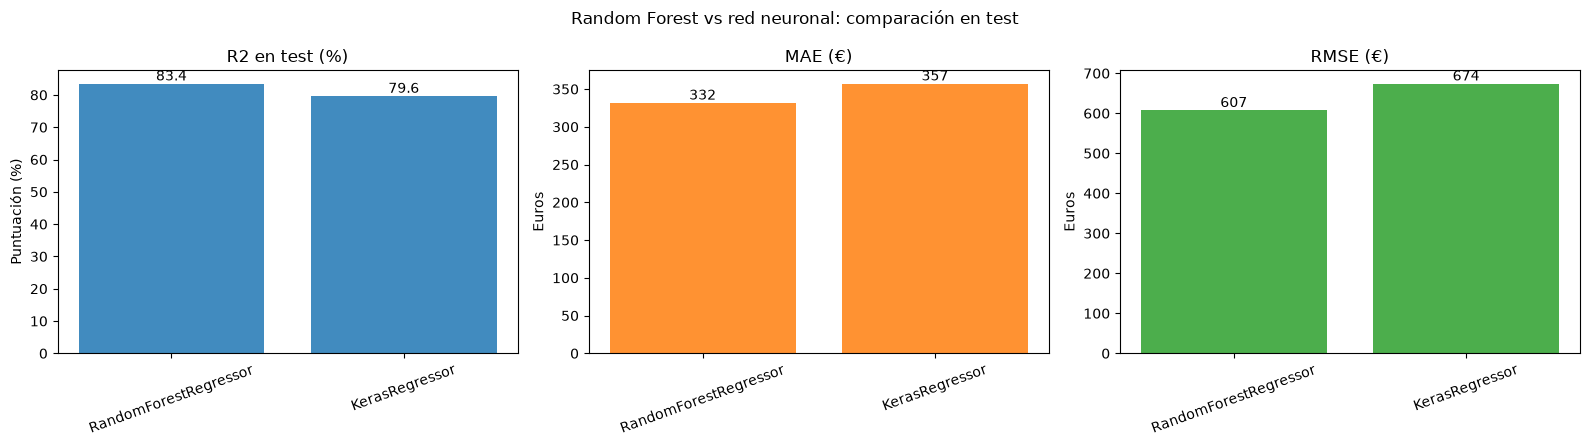

In [42]:
# comparación visual de las métricas en el mismo conjunto de test
metricas_nn = [
    ("R2 test (%)", "R2 en test (%)", "tab:blue"),
    ("MAE (€)", "MAE (€)", "tab:orange"),
    ("RMSE (€)", "RMSE (€)", "tab:green"),
]

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, (metrica, titulo, color) in zip(axes, metricas_nn):
    barras = ax.bar(df_reg_nn["Modelo"], df_reg_nn[metrica], color=color, alpha=0.85)
    ax.set_title(titulo)
    ax.set_ylabel("Puntuación (%)" if metrica == "R2 test (%)" else "Euros")
    ax.tick_params(axis="x", rotation=20)
    for barra in barras:
        ax.text(
            barra.get_x() + barra.get_width() / 2,
            barra.get_height(),
            f"{barra.get_height():.1f}" if metrica == "R2 test (%)" else f"{barra.get_height():.0f}",
            ha="center",
            va="bottom",
        )

fig.suptitle("Random Forest vs red neuronal: comparación en test")
plt.tight_layout()
plt.show()


In [43]:
def exactitud_dentro_de_euros(y_real, y_pred, tolerancia):
    error_absoluto = np.abs(y_real - y_pred)
    return (error_absoluto <= tolerancia).mean() * 100


def exactitud_dentro_de_porcentaje(y_real, y_pred, tolerancia):
    error_relativo = np.abs(y_real - y_pred) / np.maximum(np.abs(y_real), 1e-9)
    return (error_relativo <= tolerancia).mean() * 100


y_real = y_test.to_numpy(dtype=float)

y_pred_rf = a_euros(
    reg_fitted["RandomForestRegressor"].predict(X_test)
)

accuracy_rows = []

for modelo, predicciones in {
    "RandomForestRegressor": y_pred_rf,
    "KerasRegressor": y_pred_nn,
}.items():
    accuracy_rows.append({
        "Modelo": modelo,
        "Exactitud ±250 € (%)": exactitud_dentro_de_euros(
            y_real, predicciones, 250
        ),
        "Exactitud ±500 € (%)": exactitud_dentro_de_euros(
            y_real, predicciones, 500
        ),
        "Exactitud ±10 % (%)": exactitud_dentro_de_porcentaje(
            y_real, predicciones, 0.10
        ),
    })

df_accuracy = pd.DataFrame(accuracy_rows)
df_accuracy

,Modelo,Exactitud ±250 € (%),Exactitud ±500 € (%),Exactitud ±10 % (%)
0,RandomForestRegressor,63.271939,81.581798,43.391116
1,KerasRegressor,60.780065,79.035753,40.520043


Red `256 -> 128`: 59 épocas con `EarlyStopping`. Resultado: R2 = 80,0%, MAE = 359 €, RMSE = 667 €. RandomForest sigue por delante: R2 = 83,4%, MAE = 333 €, RMSE = 608 €.

La red mejora frente a modelos simples, pero no gana al RF en esta partición. No sustituye una validación con otros splits.


### Cierre de selección del regresor

Misma partición de test; métricas en euros.

**Elegimos `RandomForestRegressor` porque:**

- mayor R2 (83,4% de variabilidad explicada);
- menor MAE (333 €/anuncio);
- menor RMSE (608 €).

KNeighborsRegressor queda en medio. LinearRegression va por detrás (MAE algo mejor que KNN). El baseline `LinearRegression + floor_built` marca cuánto aportan el resto de variables.

La red Keras se acerca al variar hiperparámetros, pero no supera al RF en este ejercicio.

Seguimos con RandomForestRegressor como candidato de regresión.


## Clasificación binaria sobre `balcony`

Predecir si hay balcón (`1`) o no (`0`).

- Clase positiva ~18%: `class_weight="balanced"` donde aplique.

- Métricas: accuracy, F1, precisión, recall, matriz de confusión. **F1** es la principal (clase minoritaria).

- Cuatro enfoques: árbol, KNN, random forest y MLP.


Distribución de balcony:
balcony
sin balcón %    82.12
con balcón %    17.88
Name: proportion, dtype: float64

Train: 7383 | Test: 1846


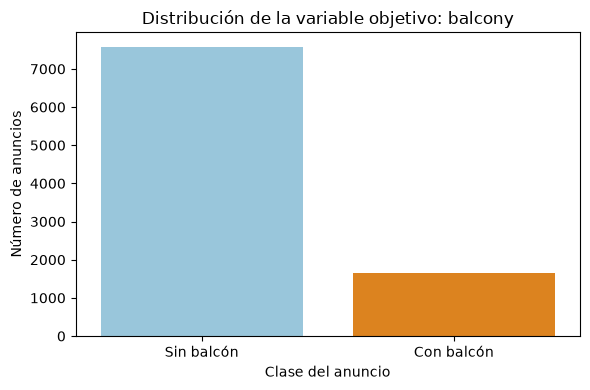

In [44]:
# clasificación sobre `balcony`
X_clf = df_model.drop(columns=["balcony"])
y_clf = df_model["balcony"].astype(int)

# La misma decisión se mantiene en clasificación: deposit no recibe imputación numérica.
assert "deposit_missing" in X_clf.columns
assert X_clf["deposit"].dtype == object
assert "deposit" not in X_clf.select_dtypes(include=np.number).columns

X_tr_c, X_te_c, y_tr_c, y_te_c = train_test_split(
    X_clf, y_clf, test_size=0.2, random_state=42, stratify=y_clf
)

# preprocesado propio de clasificación (mismas reglas, objetos nuevos)
preprocessor_clf = make_column_transformer(
    (
        make_pipeline(SimpleImputer(strategy="median"), StandardScaler()),
        make_column_selector(dtype_include=np.number),
    ),
    (
        make_pipeline(
            SimpleImputer(strategy="constant", fill_value=categoria_desconocida),
            OneHotEncoder(handle_unknown="ignore", sparse_output=False),
        ),
        make_column_selector(dtype_include=object),
    ),
)

print("Distribución de balcony:")
distribucion_balcony = y_clf.value_counts(normalize=True).mul(100).round(2).rename({0: "sin balcón %", 1: "con balcón %"})
print(distribucion_balcony)
print(f"\nTrain: {X_tr_c.shape[0]} | Test: {X_te_c.shape[0]}")

fig, ax = plt.subplots(figsize=(6, 4))
sns.countplot(
    x=y_clf.map({0: "Sin balcón", 1: "Con balcón"}),
    order=["Sin balcón", "Con balcón"],
    palette=["#8ecae6", "#fb8500"],
    hue=y_clf.map({0: "Sin balcón", 1: "Con balcón"}),
    legend=False,
    ax=ax,
)
ax.set_title("Distribución de la variable objetivo: balcony")
ax.set_xlabel("Clase del anuncio")
ax.set_ylabel("Número de anuncios")
plt.tight_layout()
plt.show()


Clase desbalanceada: muchos más anuncios sin balcón. Un modelo que diga siempre “sin balcón” tendría accuracy alto y no detectaría lo que importa.


RandomForestClassifier: CV F1 43.1 %; test F1 43.4 %; recall de balcones en test 51.2 %.
MLPClassifier: CV F1 39.8 %; test F1 41.0 %; recall de balcones en test 54.5 %.
DecisionTreeClassifier: CV F1 37.2 %; test F1 35.4 %; recall de balcones en test 54.8 %.
KNeighborsClassifier: CV F1 24.8 %; test F1 22.4 %; recall de balcones en test 14.8 %.


,Modelo,Accuracy CV (%),F1 CV (%),Precision CV (%),Recall CV (%),Accuracy test (%),F1 test (%),Precision test (%),Recall test (%)
0,RandomForestClassifier,75.66,43.11,37.28,51.44,76.11,43.39,37.64,51.21
1,MLPClassifier,70.82,39.79,31.76,53.86,71.94,41.00,32.85,54.55
2,DecisionTreeClassifier,66.61,37.19,28.23,55.08,64.14,35.35,26.08,54.85
3,KNeighborsClassifier,81.44,24.84,45.08,17.20,81.58,22.37,45.37,14.85


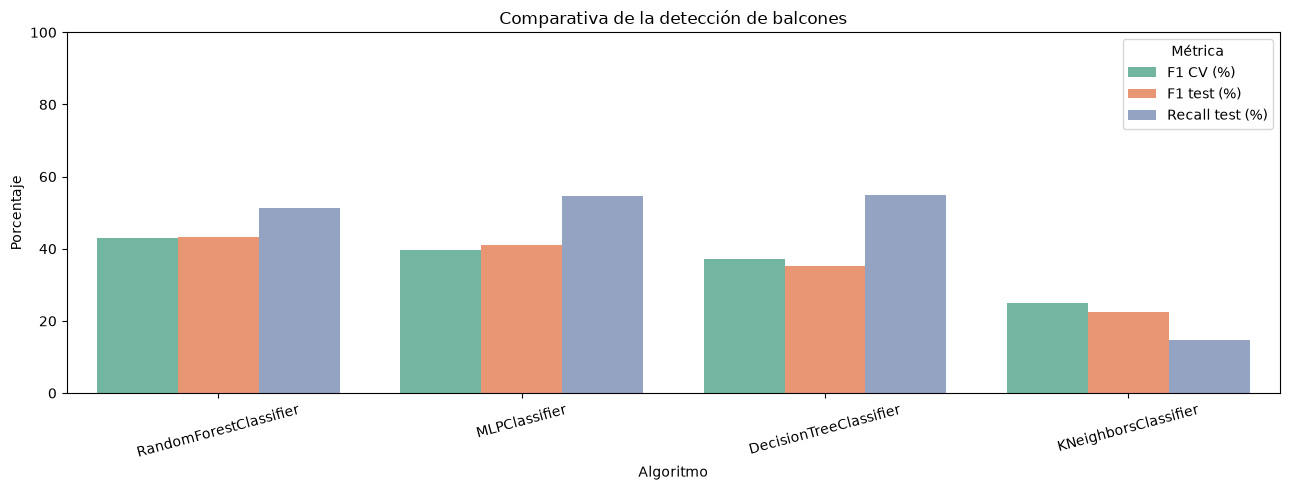

In [45]:
# comparativa de los 4 clasificadores
clf_models = {
    "DecisionTreeClassifier": DecisionTreeClassifier(
        max_depth=8, min_samples_leaf=5,
        class_weight="balanced", random_state=42,
    ),
    "KNeighborsClassifier": KNeighborsClassifier(n_neighbors=7),
    "RandomForestClassifier": RandomForestClassifier(
        n_estimators=120, max_depth=14, class_weight="balanced",
        random_state=42, n_jobs=-1,
    ),
    "MLPClassifier": MLPClassifier(
        hidden_layer_sizes=(64, 32, 16), 
        activation="relu",
        max_iter=800, 
        early_stopping=True, 
        validation_fraction=0.1,
        n_iter_no_change=20, 
        random_state=42,
    ),
}

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
clf_rows = []
clf_fitted = {}
sample_weight_mlp = compute_sample_weight("balanced", y_tr_c)

for name, model in clf_models.items():
    pipe = Pipeline(
        steps=[
            ("preprocess", clone(preprocessor_clf)),
            ("model", model),
        ]
    )
    fit_params = {}
    if name == "MLPClassifier":
        fit_params["model__sample_weight"] = sample_weight_mlp

    cv = cross_validate(
        pipe, X_tr_c, y_tr_c, cv=skf,
        scoring=["accuracy", "f1", "precision", "recall"],
        params=fit_params,
    )
    pipe.fit(X_tr_c, y_tr_c, **fit_params)
    clf_fitted[name] = pipe
    y_hat = pipe.predict(X_te_c)

    clf_rows.append({
        "Modelo": name,
        "Accuracy CV (%)": cv["test_accuracy"].mean() * 100,
        "F1 CV (%)": cv["test_f1"].mean() * 100,
        "Precision CV (%)": cv["test_precision"].mean() * 100,
        "Recall CV (%)": cv["test_recall"].mean() * 100,
        "Accuracy test (%)": accuracy_score(y_te_c, y_hat) * 100,
        "F1 test (%)": f1_score(y_te_c, y_hat, zero_division=0) * 100,
        "Precision test (%)": precision_score(y_te_c, y_hat, zero_division=0) * 100,
        "Recall test (%)": recall_score(y_te_c, y_hat, zero_division=0) * 100,
    })

df_clf = (
    pd.DataFrame(clf_rows)
    .sort_values("F1 CV (%)", ascending=False)
    .reset_index(drop=True)
)

for _, row in df_clf.iterrows():
    print(
        f"{row['Modelo']}: CV F1 {row['F1 CV (%)']:.1f} %; "
        f"test F1 {row['F1 test (%)']:.1f} %; "
        f"recall de balcones en test {row['Recall test (%)']:.1f} %."
    )

display(df_clf.round(2))

metricas_grafico = [
    "F1 CV (%)",
    "F1 test (%)",
    "Recall test (%)",
]
df_clf_grafico = df_clf.melt(
    id_vars="Modelo", value_vars=metricas_grafico,
    var_name="Métrica", value_name="Porcentaje",
)

fig, ax = plt.subplots(figsize=(13, 5))
sns.barplot(
    data=df_clf_grafico, x="Modelo", y="Porcentaje",
    hue="Métrica", palette="Set2", ax=ax,
)
ax.set_ylim(0, 100)
ax.set_title("Comparativa de la detección de balcones")
ax.set_xlabel("Algoritmo")
ax.set_ylabel("Porcentaje")
ax.tick_params(axis="x", rotation=15)
plt.tight_layout()
plt.show()


### Comparativa

No basta la accuracy: predecir siempre “sin balcón” ya acierta mucho. Usamos F1 (detección × fiabilidad) y ordenamos por F1 medio en CV.

Si CV y test se parecen, el modelo es estable. Si se separan, hay sobreajuste.


In [46]:
# evaluación del mejor clasificador en test
best_clf_name = df_clf.iloc[0]["Modelo"]
best_clf = clf_fitted[best_clf_name]
y_hat_best = best_clf.predict(X_te_c)
precision_best = precision_score(y_te_c, y_hat_best, zero_division=0)
recall_best = recall_score(y_te_c, y_hat_best, zero_division=0)
f1_best = f1_score(y_te_c, y_hat_best, zero_division=0)
accuracy_best = accuracy_score(y_te_c, y_hat_best)

df_mejor_clf = pd.DataFrame([
    {
        "Modelo": best_clf_name,
        "Accuracy (%)": accuracy_best * 100,
        "Precision (%)": precision_best * 100,
        "Recall (%)": recall_best * 100,
        "F1 (%)": f1_best * 100,
    }
])
display(df_mejor_clf.round(1))

reporte_clf = classification_report(
    y_te_c, y_hat_best,
    target_names=["Sin balcón", "Con balcón"],
    output_dict=True,
    zero_division=0,
)
df_reporte_clf = (
    pd.DataFrame(reporte_clf).T
    .rename(columns={
        "precision": "Precision",
        "recall": "Recall",
        "f1-score": "F1",
        "support": "Soporte",
    })
    .loc[
        ["Sin balcón", "Con balcón", "macro avg", "weighted avg"],
        ["Precision", "Recall", "F1", "Soporte"],
    ]
)
df_reporte_clf.index.name = "Clase"
display(df_reporte_clf.round(2))

,Modelo,Accuracy (%),Precision (%),Recall (%),F1 (%)
0,RandomForestClassifier,76.1,37.6,51.2,43.4


,Precision,Recall,F1,Soporte
Clase,,,,
Sin balcón,0.88,0.82,0.85,1516.0
Con balcón,0.38,0.51,0.43,330.0
macro avg,0.63,0.66,0.64,1846.0
weighted avg,0.79,0.76,0.77,1846.0


- **Recall 50%:** detecta 1 de cada 2 balcones reales.

- **Precisión 37%:** cuando dice balcón, acierta ~1 de cada 3 (falsos positivos).

- **F1 42,5%:** el más equilibrado. Con ~82% sin balcón, prioriza no ignorar la minoritaria aunque la accuracy baje a 75,7%.


## Conclusiones del modelado

**Regresión (`price`)**

- El baseline con `floor_built` ya explica bastante; el pipeline multivariable (encoding + escalado + Yeo-Johnson) baja el error con claridad.
- Entre tres algoritmos, `RandomForestRegressor` suele liderar en R2 y MAE en euros: captura no linealidades (distrito × superficie, amenities) que la lineal no modela bien.
- Red neuronal: R2 80,0%, MAE 359 €, RMSE 667 €, por debajo del RF (83,4%, 333 €, 608 €). Con esta arquitectura, RF es el candidato.
- Yeo-Johnson estabiliza la cola cara; al invertir, leemos R2, error medio por anuncio y un error que penaliza fallos grandes.

**Clasificación (`balcony`)**

- Con ~18% positivos, la accuracy engaña (siempre-0 ya >80%). F1, recall y matriz de confusión son las lecturas útiles.
- Mismos split y pipeline para árbol, KNN, random forest y MLP.

### Mejor clasificador

`RandomForestClassifier` gana: F1 43,7% en CV y 42,5% en test. MLP 39,5% / 39,0%; árbol 35,3% en test; KNN 24,9%.

En el mejor modelo: precisión clase balcón 36,8%, recall 50,3%. Recupera ~mitad de balcones reales, con bastantes falsos positivos. La matriz también muestra falsos negativos.

RandomForestClassifier y MLP llegan a recall de test 54,5%, pero con peor F1 (cae la precisión). Por eso no elegimos solo por recall.
